# Un masque appris de suppression de poids (gate_proj) égale-t-il LoRA et le fine-tuning complet en français sur une tâche à réponse exacte, avec moins d'oubli ?

> **En bref.** Aucune approche entraînée n'a réellement appris à cette échelle : l'hypothèse sur le masque et l'oubli reste non tranchée. La méthode n'est ni confirmée ni infirmée ; la capacité d'apprentissage du masque reste à vérifier. Exactitude (correspondance exacte) : 0 [0 ; 0] pour Deletion tuning (masque gate_proj), contre 0,03 [0 ; 0,07] pour Fine-tuning complet (100 exemples de test, échelle réduite, chiffres indicatifs).

| | |
|---|---|
| **Question** | Sur Qwen3-0.6B en SFT, le masque atteint au moins 95 % de l'exactitude du fine-tuning complet sur la classification d'intentions, avec une perte de précision hors tâche (HellaSwag français) inférieure de 1 point à celle de LoRA r=1. |
| **Référence** | LoRA rang 1 et fine-tuning complet — Deux références du même modèle de départ : LoRA r=1 sur les projections MLP et fine-tuning complet, à données et pas égaux. |
| **Nouvelle approche** | Deletion tuning (masque sur gate_proj) — Un logit par poids de gate_proj, masque doux sigmoïde progressivement durci, initialisé par un score Wanda ; seul le masque est entraîné, le modèle reste gelé. |
| **Données publiques** | [`DeepPavlov/banking77_fr`](https://huggingface.co/datasets/DeepPavlov/banking77_fr) (default) |
| **Métrique principale** | Exactitude (correspondance exacte) (à maximiser) |

**Sommaire** — 0. Mise en route · 1. La question · 2. Les données · 3. L'approche de référence · 4. La nouvelle approche · 5. Évaluation · 6. Analyse des résultats · 7. Bilan

**Trois façons d'exécuter ce notebook** (cellule de paramètres, section 0) :

| Réglage | À quoi ça sert |
|---|---|
| `PHASE = "public"`, `SCALE = "reduced"` | vérifier que tout fonctionne : quelques minutes sur CPU, sur un échantillon |
| `PHASE = "public"`, `SCALE = "full"` | reproduire les résultats publiés, sur tout le jeu public |
| `PHASE = "private"` | rejouer le même protocole sur vos données, dans votre environnement (voir le README) |

Les sorties affichées sont celles de l'échelle réduite (`SCALE = "reduced"`).

## 0. Mise en route

Trois réglages suffisent : la **phase** (quelles données), l'**échelle** (combien de données et quels modèles) et la **graine** (mêmes tirages, mêmes résultats). Le même code sert aux deux phases : seule la source des données change.

- `PHASE = "public"` charge le jeu public ; `PHASE = "private"` lit vos données d'après `PRIVATE_CONFIG` (cellule suivante) et appelle vos services internes. En phase `private`, aucune donnée brute n'est affichée.
- `SCALE = "reduced"` prend un petit échantillon et, si besoin, des modèles plus petits de la même famille : c'est un test de la mécanique, ses chiffres ne valent pas résultat. `SCALE = "full"` utilise tout le jeu.
- Les fonctions communes (chargement des données internes, appels de services, intervalles de confiance, figures, enregistrement des résultats) sont dans `helpers.py`, à côté du notebook.

Fonctions de `helpers.py` utilisées ici :

| Fonction | Rôle |
|---|---|
| `set_seed` | Graine unique pour random, numpy et torch (s'ils sont présents) : résultats reproductibles. |
| `device` | Matériel de calcul disponible : « cuda » (GPU NVIDIA), « mps » (GPU Apple) ou « cpu ». |
| `sample_size` | Nombre d'exemples à utiliser : `reduced` à l'échelle réduite, `full` (None = tout le jeu) à l'échelle complète. |
| `by_scale` | Valeur qui dépend de l'échelle : modèle substitut, nombre d'époques, de pas ou d'exemples. |
| `model_path` | Chemin à passer à `from_pretrained`, dans les deux phases : l'identifiant Hugging Face, ou son dossier local sous LOCAL_MODELS_DIR (org--nom ou org/nom), seul accessible dans un environnement sans Internet. |
| `load_private_data` | Jeu de la phase « private » : DataFrame aux colonnes attendues, lu dans PRIVATE_CONFIG['data'] (ou PRIVATE_DATA), fichier ou dossier (csv, tsv, parquet, jsonl, json, xlsx). |
| `preview` | Premières lignes en phase « public » ; en phase « private », seulement la structure (sauf SHOW_EXAMPLES=1). |
| `timer` | Mesure une durée en millisecondes : `with timer(liste): ...` ajoute la durée à `liste`. |
| `latency_stats` | Médiane (p50) et 95e centile (p95) d'une liste de durées en millisecondes. |
| `bootstrap_ci` | Valeur de `metric(y_true, y_pred)` et son intervalle de confiance à 95 % par bootstrap : (valeur, bas, haut). |
| `save_results` | Valide puis écrit results_<phase>.json dans le dossier des résultats. Structure attendue : |
| `results_table` | Tableau comparatif : une ligne par approche, chaque métrique avec son intervalle de confiance. |
| `save_figure` | Enregistre la figure (figures/<name>.png), l'affiche avec sa légende et la ferme ; ne renvoie rien. |
| `plot_comparison` | Figure de synthèse : une barre par approche et par métrique, avec l'intervalle de confiance à 95 % quand il existe. Par défaut, la métrique principale puis jusqu'à trois autres métriques. Une métrique sans objet pour une approche (None) n'a pas de barre pour elle. |

In [1]:
PHASE = "public"        # "public" : jeu public ; "private" : vos données, dans votre environnement
SCALE = "reduced"       # "reduced" : échantillon, quelques minutes sur CPU ; "full" : tout le jeu
SEED = 42               # graine : mêmes tirages, mêmes résultats
OUTPUT_DIR = "outputs"  # résultats (results_<phase>.json) et figures

### Configuration pour vos données

À modifier seulement pour `PHASE = "private"`. Chaque entrée est expliquée en commentaire ; les valeurs par défaut viennent des variables d'environnement décrites dans `private.env.example`. Au lancement, une liste de contrôle vérifie le jeu, les colonnes, les modèles et les services, et s'arrête sur ce qui manque avant tout calcul.

In [3]:
# Configuration pour vos données (PHASE = "private") : seule cellule à adapter.
# Les valeurs par défaut viennent de l'environnement (modèle : private.env.example).
# Aucune clé ici : elle vient de <SERVICE>_API_KEY, d'un fichier de secret monté (<SERVICE>_API_KEY_FILE) ou d'une saisie masquée.
import os

PRIVATE_CONFIG = {
    # Jeu de données : un fichier (csv, tsv, parquet, jsonl, json, xlsx) ou un dossier de fichiers de même structure.
    "data": os.environ.get("PRIVATE_DATA", ""),
    # Colonne attendue par le notebook -> nom de la colonne dans votre jeu (ne modifier que la partie droite).
    "columns": {'text': 'text', 'label': 'label', 'received_at': 'received_at'},
    # Colonnes qui contiennent des chemins de fichiers (relatifs au fichier de données qui les cite, ou absolus).
    "path_columns": [],
    "max_rows": None,                         # plafond facultatif (échantillon aléatoire reproductible)
    "csv": {"sep": None, "encoding": None},   # None : séparateur et encodage devinés (« ; », Windows-1252…)
    # Poids des modèles copiés localement (dossiers org--nom/, script download_models.py), pour travailler sans Internet.
    "models_dir": os.environ.get("LOCAL_MODELS_DIR", ""),
    "models": {'reduced': ['Qwen/Qwen3-0.6B'], 'full': ['Qwen/Qwen3-0.6B']},
    # Autorité de certification d'entreprise (fichier PEM) pour les appels HTTPS internes ; vide sinon.
    "ca_bundle": os.environ.get("SSL_CERT_FILE", ""),
}

### Dépendances et initialisation

Les versions exactes utilisées pour les résultats publiés sont dans `requirements.txt`. Les paquets propres à cette expérience s'installent depuis le notebook avec `INSTALL_DEPENDENCIES=1`.

In [4]:
# Paquets propres à cette expérience (en plus de requirements.txt).
EXTRA_PACKAGES = ['peft']
import os, subprocess, sys
if EXTRA_PACKAGES and os.environ.get("INSTALL_DEPENDENCIES") == "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *EXTRA_PACKAGES])

In [5]:
from helpers import *  # fonctions communes (voir le tableau ci-dessus)

configure(phase=PHASE, scale=SCALE, seed=SEED, output_dir=OUTPUT_DIR)
apply_private_config(PRIVATE_CONFIG)  # phase private : liste de contrôle, arrêt si quelque chose manque
prepare_environment()                 # télémétrie coupée ; hors ligne si les modèles sont locaux
use_plot_style()
show_configuration()

PHASE=public  SCALE=reduced  SEED=42  device=cpu  python=3.12.16
service LLM (convention OpenAI)               LLMAAS_BASE_URL=—  LLMAAS_MODEL=—  clé absente
service de transcription (convention OpenAI)  STTAAS_BASE_URL=—  STTAAS_MODEL=—  clé absente
données internes : —  modèles locaux : —


## 1. La question

Un modèle de langue préentraîné peut-il apprendre une tâche nouvelle **sans qu'on change la valeur d'un seul poids**, en choisissant seulement quelques poids à **mettre à zéro** ? Un preprint récent (*The Surprising Effectiveness of Deleting Weights in LLM Post-Training*, 2026) l'affirme. Selon lui, supprimer moins de 0,05 % des poids égale le **fine-tuning complet**, avec un adaptateur de quelques Mo et moins d'**oubli** des capacités antérieures. Ses tests portent sur l'anglais et sur des modèles de 0,5 à 30 milliards de paramètres.

On le vérifie ici **en français**, sur une tâche à réponse exacte : attribuer à une courte demande de client d'un service financier (carte, virement, compte…) l'une de **77 intentions**.

### L'idée, en image

Pensez à un **sculpteur qui n'a pas le droit d'ajouter de matière** : il ne peut que retirer. Le *deletion tuning* adapte le modèle de la même façon. Il garde le bloc de départ et choisit les rares éclats à enlever.

1. Le modèle reste **gelé**. Chaque poids de la matrice `gate_proj` (une des trois matrices du bloc MLP de chaque couche) reçoit un score appris, son **logit**.
2. Pendant l'entraînement, chaque poids est multiplié par un **masque doux** $\sigma(\ell/\tau)$ entre 0 et 1. On baisse la température $\tau$ peu à peu, si bien que le masque devient presque binaire.
3. Les logits partent du score **Wanda** (|poids| × norme de l'activation d'entrée), qui supprime d'emblée ≈ 0,18 % des poids.
4. La perte reste celle d'un fine-tuning supervisé ordinaire : prédire le nom de la classe.
5. Au déploiement, un logit positif garde le poids et un logit négatif le met à zéro. L'adaptateur tient en **un bit par poids**, compressé.

### Ce que la comparaison permet de décider

- **Qualité** : le masque atteint-il au moins 95 % de l'exactitude du fine-tuning complet (FFT) ? Fait-il au moins aussi bien que **LoRA rang 1** ?
- **Oubli** : sur HellaSwag en français, un test de bon sens qui n'a rien à voir avec la tâche, le masque perd-il au moins 1 point de moins que LoRA ?
- **Coût** : quelle taille d'adaptateur par tâche, et combien de paramètres entraînés ?

On ne compare l'oubli que si les deux bras ont **vraiment appris** la tâche. Sinon, « moins d'oubli » voudrait seulement dire « rien n'a changé ».

Attention : le modèle étudié (Qwen3-0.6B) est petit. Les auteurs eux-mêmes n'observent pas l'égalité avec le FFT à cette taille. Un écart en faveur du FFT ne contredirait donc pas l'article.

## 2. Les données

### Sources et tailles d'échantillon

On utilise trois jeux publics :
- **`DeepPavlov/banking77_fr`** : traduction française d'un jeu de 13 000 demandes clients réparties en 77 intentions. Les étiquettes y sont des **indices**.
- **`mteb/banking77`** : la version anglaise d'origine, qui donne le **nom** de chaque classe (`card_arrival`…). On fait correspondre les deux versions par indice.
- **`manu/french_bench_hellaswag`** : choisir la fin la plus plausible d'une phrase parmi 4. Il sert à **mesurer l'oubli**.

Les tailles dépendent de l'échelle (`sample_size`). Le test garde au moins 100 exemples.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

DATASET_ID = "DeepPavlov/banking77_fr"            # demandes clients traduites en français, 77 intentions
DATASET_CONFIG = "default"                         # unique configuration du jeu
LABEL_NAMES_ID = "mteb/banking77"                  # version anglaise d'origine : porte les noms des classes
CONTROL_DATASET_ID = "manu/french_bench_hellaswag" # contrôle d'oubli : bon sens en français
CONTROL_SPLIT = "validation"                       # partie d'évaluation du contrôle
N_TRAIN = sample_size(reduced=100, full=3000)      # exemples d'entraînement, identiques pour tous les bras
N_TEST = sample_size(reduced=100, full=1000)       # exemples de test (jamais moins de 100)
N_CONTROL = sample_size(reduced=16, full=500)      # exemples HellaSwag pour mesurer l'oubli

print(f"Entraînement : {N_TRAIN} | test : {N_TEST} | contrôle d'oubli : {N_CONTROL}")

Entraînement : 100 | test : 100 | contrôle d'oubli : 16


/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Mise au format commun

Quatre petites fonctions :
- `load_label_names` lit les noms de classes dans la version anglaise.
- `alignment_share` **vérifie l'alignement par indice**. Le jeu français est une traduction ligne à ligne : chaque classe doit donc avoir le même effectif dans les deux versions. Si ce n'est pas le cas, les noms de classes seraient faux et l'expérience n'aurait plus de sens.
- `to_standard` et `to_control` ramènent les jeux aux colonnes `text` / `label`, ou `context` / `endings` / `label`, et écartent les lignes vides ou mal formées.

In [7]:
def load_label_names() -> tuple[dict[int, str], pd.DataFrame]:
    """Lit la version anglaise ; rend la correspondance indice -> nom de classe et ce jeu."""
    english = load_dataset(LABEL_NAMES_ID, split="train").to_pandas()
    pairs = english[["label", "label_text"]].drop_duplicates()
    assert pairs["label"].is_unique, "un indice porte plusieurs noms de classe"
    return dict(zip(pairs["label"].astype(int), pairs["label_text"].astype(str))), english


def alignment_share(french: pd.DataFrame, english: pd.DataFrame) -> float:
    """Part des classes dont l'effectif est identique dans les deux versions (alignement par indice)."""
    counts = pd.concat([french["label"].astype(int).value_counts(), english["label"].astype(int).value_counts()],
                       axis=1, keys=["fr", "en"]).fillna(0)
    return float((counts["fr"] == counts["en"]).mean())


def to_standard(frame: pd.DataFrame, label_names: dict[int, str]) -> pd.DataFrame:
    """Format commun : `text` (chaîne) et `label` (nom de classe)."""
    assert {"utterance", "label"} <= set(frame.columns), f"colonnes inattendues : {list(frame.columns)}"
    out = pd.DataFrame({"text": frame["utterance"].astype(str).str.strip(),
                        "label": frame["label"].astype(int).map(label_names)})
    assert out["label"].notna().all(), "indice de classe sans nom"
    return out[out["text"].str.len() > 0].reset_index(drop=True)


def to_control(frame: pd.DataFrame) -> pd.DataFrame:
    """Format du contrôle d'oubli : contexte, 4 fins possibles, indice de la bonne fin."""
    assert {"ctx", "endings", "label"} <= set(frame.columns), f"colonnes inattendues : {list(frame.columns)}"
    out = pd.DataFrame({"context": frame["ctx"].astype(str).str.strip(),
                        "endings": frame["endings"].map(lambda e: [str(x).strip() for x in e]),
                        "label": pd.to_numeric(frame["label"], errors="coerce")})
    valid = (out["label"].between(0, 3) & out["context"].str.len().gt(0)
             & out["endings"].map(lambda e: len(e) == 4 and all(e)))
    out = out[valid].reset_index(drop=True)
    out["label"] = out["label"].astype(int)
    return out

### Échantillonnage, contrôles et figure

Ces fonctions servent **dans les deux phases**, sur le jeu public comme sur les données internes :
- `sample_rows` tire un échantillon au hasard avec la graine de l'expérience, donc reproductible.
- `describe_split` donne les effectifs, le nombre de classes, le minimum et le maximum d'exemples par classe, et la longueur des textes.
- `plot_data` montre la répartition des classes et la distribution des longueurs.

In [8]:
def sample_rows(frame: pd.DataFrame, n: int | None, seed: int) -> pd.DataFrame:
    """Tire `n` lignes au hasard avec la graine (tout le jeu, mélangé, si `n` est None ou trop grand)."""
    n = len(frame) if n is None else min(n, len(frame))
    return frame.sample(n=n, random_state=seed).reset_index(drop=True)


def describe_split(train: pd.DataFrame, test: pd.DataFrame) -> pd.DataFrame:
    """Effectifs, couverture des classes et longueurs (en mots) de chaque partie."""
    rows = []
    for name, frame in (("entraînement", train), ("test", test)):
        counts, words = frame["label"].value_counts(), frame["text"].str.split().str.len()
        rows.append({"partie": name, "exemples": len(frame), "classes": int(frame["label"].nunique()),
                     "min par classe": int(counts.min()), "max par classe": int(counts.max()),
                     "mots (médiane)": float(words.median()), "mots (max)": int(words.max())})
    unseen = set(test["label"]) - set(train["label"])
    print(f"Classes du test absentes de l'entraînement : {len(unseen)}")
    return pd.DataFrame(rows)


def plot_data(train: pd.DataFrame, test: pd.DataFrame) -> None:
    """Figure : exemples par classe (entraînement) et distribution des longueurs de texte."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    counts = train["label"].value_counts()
    axes[0].bar(np.arange(len(counts)), counts.to_numpy(), color=COLORS["reference"])
    axes[0].set(title="Exemples d'entraînement par classe", xlabel="classes, de la plus à la moins fréquente",
                ylabel="nombre d'exemples")
    for frame, name, color in ((train, "entraînement", COLORS["reference"]), (test, "test", COLORS["accent"])):
        axes[1].hist(frame["text"].str.split().str.len(), bins=25, alpha=0.6, label=name, color=color)
    axes[1].set(title="Longueur des textes", xlabel="longueur (mots)", ylabel="nombre de textes")
    axes[1].legend()
    save_figure(fig, "data_overview", "À gauche, le nombre d'exemples d'entraînement par classe (une barre par "
                "classe, triées) ; à droite, la longueur des textes en mots, entraînement et test superposés.")

### Chargement du jeu public

Cette cellule ne s'exécute qu'en phase publique. Elle charge les trois jeux, vérifie l'alignement des noms de classes, puis tire les échantillons d'entraînement, de test et de contrôle. Le test vient de la partie `test` officielle, jamais vue à l'entraînement. Enfin, elle affiche les contrôles, la figure et quelques exemples.

Classes aux effectifs identiques entre versions française et anglaise : 88%


77 classes ; contrôle d'oubli : 16 exemples sur 9338 valides
Classes du test absentes de l'entraînement : 16


,partie,exemples,classes,min par classe,max par classe,mots (médiane),mots (max)
0,entraînement,100,55,1,6,10.5,64
1,test,100,57,1,5,11.0,46


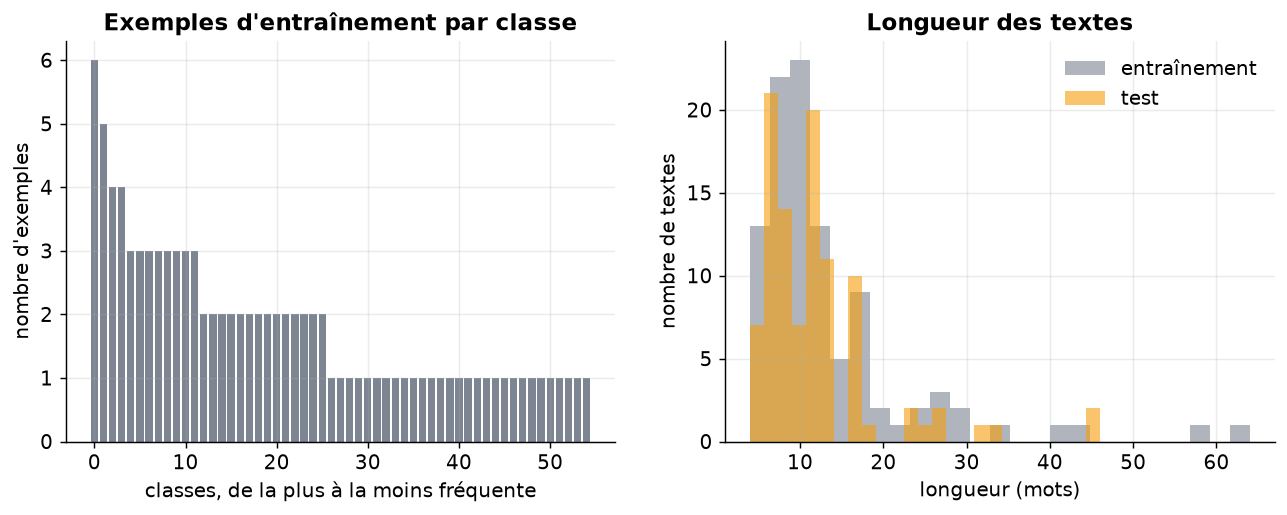

*Figure — À gauche, le nombre d'exemples d'entraînement par classe (une barre par classe, triées) ; à droite, la longueur des textes en mots, entraînement et test superposés.*

In [9]:
if PHASE == "public":
    label_names, english_train = load_label_names()
    french = load_dataset(DATASET_ID, DATASET_CONFIG)
    share = alignment_share(french["train"].to_pandas(), english_train)
    print(f"Classes aux effectifs identiques entre versions française et anglaise : {share:.0%}")
    assert share >= 0.8, "indices de classes non alignés : les noms de classes ne seraient pas fiables"
    train_pool = to_standard(french["train"].to_pandas(), label_names)
    test_pool = to_standard(french["test"].to_pandas(), label_names)
    control_pool = to_control(load_dataset(CONTROL_DATASET_ID, split=CONTROL_SPLIT).to_pandas())
    train = sample_rows(train_pool, N_TRAIN, SEED)
    test = sample_rows(test_pool, N_TEST, SEED)
    control = sample_rows(control_pool, N_CONTROL, SEED)
    classes = sorted(label_names.values())
    DATA_NAME, DATA_CONFIG = DATASET_ID, DATASET_CONFIG
    print(f"{len(classes)} classes ; contrôle d'oubli : {len(control)} exemples sur {len(control_pool)} valides")
    display(describe_split(train, test))
    plot_data(train, test)
    preview(train)

### Données internes : colonnes attendues et jeu factice

En phase `private`, le jeu est lu par `load_private_data`, sur trois colonnes : le texte anonymisé, la classe exacte et la date de réception. Pour valider le code sans aucune donnée réelle, `make_fake_data` fabrique des demandes plausibles et courtes autour de cartes de paiement, comptes et virements, avec une date de réception aléatoire sur un an. Les classes y sont différentes du jeu public, exprès : le code doit les **déduire des données**.

In [10]:
PRIVATE_COLUMNS = {"text": "Texte à classer, anonymisé",
                   "label": "Classe cible exacte",
                   "received_at": "Date de réception"}
TEST_SHARE = 0.25  # part la plus récente des données réservée au test (découpage temporel)
N_FAKE = 520       # lignes du jeu factice : assez pour 100 exemples de test et ≥ 20 par classe

FAKE_INTENTS = {
    "carte_bloquee": ["Ma carte de paiement est bloquée depuis {when}.", "Ma carte est refusée partout {when}.",
                      "Pourquoi ma carte ne passe plus {when} ?"],
    "virement_en_attente": ["Mon virement de {amount} euros est toujours en attente.",
                            "Le virement envoyé {when} n'est pas arrivé.", "Où en est mon virement de {amount} € ?"],
    "plafond_carte": ["Comment augmenter le plafond de ma carte ?", "Je voudrais relever ma limite à {amount} euros.",
                      "Mon paiement de {amount} € a dépassé le plafond {when}."],
    "frais_inconnus": ["Je vois des frais de {amount} euros que je ne comprends pas.",
                       "Pourquoi m'a-t-on prélevé {amount} euros {when} ?", "Quels sont ces frais apparus {when} ?"],
    "ouverture_compte": ["Quels documents faut-il pour ouvrir un compte ?", "Je souhaite ouvrir un compte joint.",
                         "J'ai commencé l'ouverture de mon compte {when}, que faire ensuite ?"],
    "changement_adresse": ["Comment modifier mon adresse postale ?", "J'ai déménagé {when}, où changer mes coordonnées ?",
                           "Mon adresse n'est plus à jour sur mon compte."],
    "code_oublie": ["J'ai oublié le code de ma carte.", "Mon code secret ne fonctionne plus depuis {when}.",
                    "Comment retrouver le code de ma carte de paiement ?"],
    "remboursement_absent": ["Je n'ai pas reçu le remboursement de {amount} euros.",
                             "Un marchand devait me rembourser {when}, rien n'est arrivé.",
                             "Le remboursement de {amount} € n'apparaît pas sur mon compte."],
}
FAKE_WHEN = ["hier", "ce matin", "lundi", "la semaine dernière", "depuis trois jours", "ce week-end"]
FAKE_OPENINGS = ["", "Bonjour, ", "Bonsoir, ", "Rebonjour, ", "Question : "]

### Générateur de jeu factice

On tire une classe, puis un gabarit de phrase, puis des valeurs : moment, montant, formule d'ouverture. On obtient ainsi des textes variés mais réalistes. Les dates sont rendues **en texte**, comme dans un fichier exporté : la lecture devra les convertir explicitement.

In [11]:
def make_fake_data(n: int) -> pd.DataFrame:
    """Jeu factice plausible : demandes courtes, classe exacte, date de réception (aucune donnée réelle)."""
    rng = np.random.default_rng(SEED)
    labels = rng.choice(sorted(FAKE_INTENTS), size=n)
    texts = []
    for label in labels:
        template = str(rng.choice(FAKE_INTENTS[str(label)]))
        filled = template.format(when=str(rng.choice(FAKE_WHEN)), amount=int(rng.integers(5, 2000)))
        opening = str(rng.choice(FAKE_OPENINGS))
        texts.append(opening + (filled[0].lower() + filled[1:] if opening else filled))
    seconds = rng.integers(0, 365 * 24 * 3600, size=n)
    received = pd.Timestamp("2025-01-01") + pd.to_timedelta(seconds, unit="s")
    return pd.DataFrame({"text": texts, "label": [str(x) for x in labels],
                         "received_at": [str(t) for t in received]})

### Chargement et découpage temporel

En phase `private` seulement :
- **conversion explicite des types** : texte, classe en chaîne, date ;
- retrait des lignes inutilisables ;
- **découpage temporel** : les 25 % de demandes les plus récentes forment le test. C'est ainsi que le modèle servirait : entraîné sur le passé, évalué sur des demandes plus récentes.

On applique ensuite les mêmes échantillonnages et contrôles qu'en phase publique. Ces colonnes ne fournissent aucun jeu de contrôle d'oubli : `control` vaut `None`, et les métriques d'oubli vaudront `None`.

In [12]:
if PHASE == "private":
    raw = load_private_data(PRIVATE_COLUMNS, make_fake_data, n_fake=N_FAKE)
    raw = raw.dropna(subset=["text", "label", "received_at"])
    data = pd.DataFrame({"text": raw["text"].astype(str).str.strip(),
                         "label": raw["label"].astype(str).str.strip(),
                         "received_at": pd.to_datetime(raw["received_at"], errors="coerce", utc=True)})
    data = data.dropna(subset=["received_at"])
    data = data[(data["text"].str.len() > 0) & (data["label"].str.len() > 0)]
    data = data.sort_values("received_at", kind="stable").reset_index(drop=True)
    n_recent = int(round(TEST_SHARE * len(data)))
    train_pool, test_pool = data.iloc[:-n_recent], data.iloc[-n_recent:]
    train = sample_rows(train_pool, N_TRAIN, SEED)
    test = sample_rows(test_pool, N_TEST, SEED)
    classes = sorted(data["label"].unique())
    control = None  # pas de jeu de contrôle hors tâche parmi les colonnes fournies
    DATA_NAME, DATA_CONFIG = "données internes", "découpage temporel"
    print(f"{len(data)} lignes valides, {len(classes)} classes ; test = {TEST_SHARE:.0%} les plus récentes")
    assert len(test) >= 100, "moins de 100 exemples de test : évaluation non concluante"
    display(describe_split(train, test))
    plot_data(train, test)
    preview(train)

## 3. L'approche de référence

### Réglages communs aux quatre bras

Les quatre bras partent du même modèle, **Qwen3-0.6B**, à la révision épinglée. Ils voient les mêmes exemples, dans le même ordre, en lots de 16, pendant une époque.
- **FFT** : taux d'apprentissage de 1e-5 (plan).
- **LoRA r=1** : 2e-4 sur les trois projections MLP (plan).
- Le **taux d'apprentissage** suit une montée linéaire sur 10 % des pas, puis une décroissance linéaire.
- **Micro-lots** : chaque lot de 16 passe par morceaux de `MICRO_BATCH_SIZE` exemples, et leurs gradients s'additionnent (*accumulation de gradients*). La mise à jour est la même qu'avec le lot entier, mais il faut beaucoup moins de mémoire pour les activations. C'est ce qui permet au FFT de tenir en mémoire sur CPU.

Sur GPU, le calcul passe en **précision mixte float16**. Sur CPU, il reste en float32.

In [13]:
import contextlib
import ctypes
import gc
import sys
import time
import torch
import transformers
import peft
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig
from peft import LoraConfig, PeftModel, get_peft_model

MODEL_ID = "Qwen/Qwen3-0.6B"                                 # modèle étudié, identique aux deux échelles
MODEL_REVISION = "c1899de289a04d12100db370d81485cdf75e47ca"  # révision épinglée du Hub
MAX_TEXT_TOKENS = by_scale(reduced=64, full=96)      # plafond d'un texte à classer (tokens)
MAX_CONTEXT_TOKENS = by_scale(reduced=64, full=160)  # plafond du contexte HellaSwag, coupé à gauche
BATCH_SIZE = 16                 # exemples par pas d'entraînement (plan)
MICRO_BATCH_SIZE = by_scale(reduced=4, full=8)  # sous-lot rétropropagé d'un coup (mémoire des activations)
N_EPOCHS = 1                    # une seule passe sur les données (plan)
WARMUP_SHARE = 0.1              # part des pas en montée linéaire du taux d'apprentissage
EVAL_BATCH_SIZE = by_scale(reduced=25, full=64)        # textes générés en parallèle
CONTROL_BATCH_SIZE = by_scale(reduced=4, full=8)       # exemples HellaSwag (×4 fins) notés ensemble
FEW_SHOT = 5                    # exemples montrés au modèle sans entraînement (plan)
GENERATION_BUDGET_S = by_scale(reduced=480, full=900)  # budget de génération par bras (secondes)
MIN_EVALUATED = 100             # minimum d'exemples de test évalués par bras
LORA_RANK = 1                   # rang LoRA (plan)
LORA_ALPHA = 16                 # échelle LoRA : mise à jour × alpha / rang
LORA_LR = 2e-4                  # taux d'apprentissage LoRA (plan)
FFT_LR = 1e-5                   # taux d'apprentissage du fine-tuning complet (plan)
DEVICE = device()
USE_FP16 = DEVICE == "cuda"     # précision mixte seulement sur GPU

print(f"Matériel : {DEVICE} | précision mixte : {USE_FP16} | plafond texte : {MAX_TEXT_TOKENS} tokens | "
      f"micro-lot : {MICRO_BATCH_SIZE}")

Matériel : cpu | précision mixte : False | plafond texte : 64 tokens | micro-lot : 4


### Tokeniseur et format des exemples

Tous les bras utilisent le même format, **sans gabarit de conversation** : `Texte : <demande>\nIntention : <classe>\n`. La **réponse s'arrête au premier saut de ligne**. On repère donc tous les tokens du vocabulaire qui en contiennent un : en BPE à octets, `\n` s'écrit « Ċ ». Le texte est tronqué à `MAX_TEXT_TOKENS`, et la part coupée est mesurée juste après.

In [14]:
model_source = model_path(MODEL_ID)
load_kwargs = {"revision": MODEL_REVISION} if model_source == MODEL_ID else {}
tokenizer = AutoTokenizer.from_pretrained(model_source, **load_kwargs)
PAD_ID = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id
# Tout token qui contient un saut de ligne termine la réponse générée.
STOP_IDS = sorted({i for token, i in tokenizer.get_vocab().items() if "Ċ" in token} | {tokenizer.eos_token_id})


def tokens(text: str) -> list[int]:
    """Identifiants de tokens d'un texte, sans token spécial."""
    return tokenizer(text, add_special_tokens=False)["input_ids"]


PROMPT_START, PROMPT_END = tokens("Texte : "), tokens("\nIntention :")
assert tokens("\n")[0] in STOP_IDS, "le saut de ligne n'est pas reconnu comme fin de réponse"


def prompt_ids(text: str) -> list[int]:
    """Invite d'un exemple : « Texte : … \\nIntention : », texte tronqué à MAX_TEXT_TOKENS."""
    return PROMPT_START + tokens(text)[:MAX_TEXT_TOKENS] + PROMPT_END


def target_ids(label: str) -> list[int]:
    """Réponse attendue : un espace, le nom de la classe, un saut de ligne."""
    return tokens(" " + label + "\n")


def clean_output(text: str) -> str:
    """Réponse générée réduite à sa première ligne, sans espaces autour."""
    return text.split("\n")[0].strip()


print(f"Tokeniseur chargé ; {len(STOP_IDS)} tokens de fin de réponse")

Tokeniseur chargé ; 2179 tokens de fin de réponse


### Longueur des entrées en tokens

Une entrée coupée peut perdre l'indice qui donne la classe. On mesure donc les longueurs **avant toute inférence** et on affiche la part coupée, globale et dans la pire classe. La cible est de garder au moins 95 % des textes entiers. À l'échelle réduite, une classe qui n'a qu'un exemple, et dont cet exemple est long, peut afficher 100 % de textes coupés. On mesure aussi le contexte HellaSwag, coupé à gauche pour garder la fin de phrase, et la longueur maximale d'un nom de classe, qui fixe le nombre de tokens à générer.

In [15]:
def length_table(frames: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Longueurs en tokens et part des textes coupés par MAX_TEXT_TOKENS, globalement et dans la pire classe."""
    rows = []
    for name, frame in frames.items():
        lengths = frame["text"].map(lambda t: len(tokens(t)))
        cut = lengths > MAX_TEXT_TOKENS
        rows.append({"partie": name, "médiane (tokens)": float(lengths.median()),
                     "p95 (tokens)": float(lengths.quantile(0.95)), "max (tokens)": int(lengths.max()),
                     "part coupée": float(cut.mean()), "part coupée (pire classe)": float(cut.groupby(frame["label"]).mean().max())})
    return pd.DataFrame(rows).round(3)


lengths_report = length_table({"entraînement": train, "test": test})
display(lengths_report)
if lengths_report["part coupée (pire classe)"].max() > 0.05:
    print("Attention : plus de 5 % des textes d'une classe sont coupés ; résultats à lire avec prudence.")
if control is not None:
    context_lengths = control["context"].map(lambda t: len(tokens(t)))
    print(f"Contexte HellaSwag : médiane {context_lengths.median():.0f} tokens, "
          f"part coupée à {MAX_CONTEXT_TOKENS} : {(context_lengths > MAX_CONTEXT_TOKENS).mean():.1%}")
MAX_NEW_TOKENS = max(len(target_ids(c)) for c in classes) + 2  # nom de classe le plus long + marge
print(f"Tokens générés au plus par réponse : {MAX_NEW_TOKENS}")

,partie,médiane (tokens),p95 (tokens),max (tokens),part coupée,part coupée (pire classe)
0,entraînement,17.0,54.30,93,0.03,1.0
1,test,17.0,38.35,79,0.02,1.0


Attention : plus de 5 % des textes d'une classe sont coupés ; résultats à lire avec prudence.
Contexte HellaSwag : médiane 74 tokens, part coupée à 64 : 68.8%
Tokens générés au plus par réponse : 12


### Chargement du modèle et relevé de ce qui tourne

`load_base_model` recharge à chaque bras les **poids d'origine**, en float32. Aucun bras n'hérite donc de l'entraînement d'un autre. `describe_model` relève ce qui tourne vraiment (classe, attention, précision, versions), et ce relevé est gardé avec les résultats. `causal_lm` donne accès au modèle sous-jacent quand LoRA l'enveloppe. `free_memory` libère la mémoire entre deux bras. Sous Linux, elle appelle aussi `malloc_trim`, qui **rend au système** la mémoire libérée : sinon, elle resterait réservée par le processus et s'ajouterait au pic du bras suivant.

In [16]:
def load_base_model() -> torch.nn.Module:
    """Charge le modèle préentraîné (révision épinglée) en float32 sur le matériel de calcul."""
    model = AutoModelForCausalLM.from_pretrained(model_source, **load_kwargs)
    model = model.to(device=DEVICE, dtype=torch.float32).eval()
    assert next(model.parameters()).dtype == torch.float32, "poids non convertis en float32"
    return model


def describe_model(model: torch.nn.Module) -> dict:
    """Relevé de ce qui tourne : modèle, attention, précision, matériel et versions."""
    return {"modèle": MODEL_ID, "révision": MODEL_REVISION if load_kwargs else "dossier local",
            "classe": type(model).__name__, "attention": str(getattr(model.config, "_attn_implementation", "inconnue")),
            "poids": str(next(model.parameters()).dtype), "calcul": "autocast float16" if USE_FP16 else "float32",
            "matériel": DEVICE, "transformers": transformers.__version__, "peft": peft.__version__,
            "torch": torch.__version__, "paramètres": f"{sum(p.numel() for p in model.parameters()):,}"}


def causal_lm(model: torch.nn.Module) -> torch.nn.Module:
    """Modèle causal sous-jacent (retire l'enveloppe LoRA si présente)."""
    return model.get_base_model() if isinstance(model, PeftModel) else model


def autocast_context():
    """Précision mixte float16 sur GPU, calcul float32 ordinaire sinon."""
    return torch.autocast("cuda", dtype=torch.float16) if USE_FP16 else contextlib.nullcontext()


def free_memory() -> None:
    """Libère la mémoire entre deux bras et la rend au système (glibc) sous Linux."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if sys.platform.startswith("linux"):
        ctypes.CDLL("libc.so.6").malloc_trim(0)  # sans cela, la mémoire libérée reste réservée au processus

### Log-probabilités des tokens cibles

C'est le cœur commun de l'entraînement et du contrôle d'oubli : pour chaque token de la réponse, $\log p(\text{token} \mid \text{ce qui précède})$.
- La **perte SFT** est l'opposé de leur moyenne. Elle porte sur la réponse seule, pas sur la demande.
- La **tête de sortie**, qui projette sur ~152 000 tokens, n'est appliquée qu'aux positions utiles. C'est un gros gain de calcul sur CPU.

In [17]:
def pad_batch(sequences: list[list[int]], left: bool = False) -> tuple[torch.Tensor, torch.Tensor]:
    """Aligne des séquences de longueurs différentes (`left=True` pour la génération).

    Rend les identifiants et le masque d'attention (1 = vrai token, 0 = remplissage)."""
    width = max(len(seq) for seq in sequences)
    ids = torch.full((len(sequences), width), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(sequences), width), dtype=torch.long)
    for row, seq in enumerate(sequences):
        span = slice(width - len(seq), width) if left else slice(0, len(seq))
        ids[row, span] = torch.tensor(seq, dtype=torch.long)
        mask[row, span] = 1
    return ids.to(DEVICE), mask.to(DEVICE)


def target_logprobs(model: torch.nn.Module, prompts: list[list[int]], targets: list[list[int]]) -> list[torch.Tensor]:
    """Log-probabilité de chaque token cible sachant ce qui le précède ; un tenseur par séquence."""
    lm = causal_lm(model)
    ids, mask = pad_batch([p + t for p, t in zip(prompts, targets)])
    # Le token j de la cible est prédit par l'état caché de la position précédente.
    rows = torch.tensor([r for r, t in enumerate(targets) for _ in t], device=DEVICE)
    cols = torch.tensor([len(p) - 1 + j for p, t in zip(prompts, targets) for j in range(len(t))], device=DEVICE)
    flat_targets = torch.tensor([tok for t in targets for tok in t], device=DEVICE)
    with autocast_context():
        hidden = lm.model(input_ids=ids, attention_mask=mask, use_cache=False).last_hidden_state
        logits = lm.get_output_embeddings()(hidden[rows, cols])
    logprobs = torch.log_softmax(logits.float(), dim=-1)
    token_logprobs = logprobs.gather(1, flat_targets[:, None]).squeeze(1)
    return list(token_logprobs.split([len(t) for t in targets]))

### Perte d'un lot, calculée par micro-lots

`backward_in_chunks` découpe un lot de 16 en sous-lots de `MICRO_BATCH_SIZE`. Chaque morceau est rétropropagé aussitôt, puis ses activations sont libérées. La somme des log-probabilités de chaque morceau est divisée par le **nombre total de tokens cibles du lot**. Les gradients additionnés valent donc exactement ceux de la perte moyenne sur le lot entier : $\mathcal{L} = -\frac{1}{N}\sum_{\text{tokens}} \log p$.

In [18]:
def backward_in_chunks(model: torch.nn.Module, prompts: list[list[int]], answers: list[list[int]],
                       scaler: torch.amp.GradScaler) -> float:
    """Rétropropage la perte SFT moyenne d'un lot, sous-lot par sous-lot ; rend la valeur de cette perte."""
    n_target_tokens = sum(len(answer) for answer in answers)
    batch_loss = 0.0
    for begin in range(0, len(prompts), MICRO_BATCH_SIZE):
        chunk = slice(begin, begin + MICRO_BATCH_SIZE)
        logprobs = target_logprobs(model, prompts[chunk], answers[chunk])
        loss = -torch.cat(logprobs).sum() / n_target_tokens  # même normalisation que sur le lot entier
        scaler.scale(loss).backward()  # les gradients s'additionnent d'un sous-lot à l'autre
        batch_loss += float(loss.detach())
    return batch_loss

### Boucle d'entraînement commune

Une seule fonction entraîne les trois bras : seuls les **paramètres libres** et le **taux d'apprentissage** changent.
- L'ordre des lots est tiré une fois avec la graine, donc identique pour tous.
- L'optimiseur est AdamW, avec une montée puis une décroissance linéaire du taux d'apprentissage.
- La norme du gradient est écrêtée à 1.
- Les gradients sont **effacés juste après chaque pas**, pour ne pas occuper la mémoire pendant le passage suivant.
- Un rappel `on_step` permet au masque de baisser sa température à chaque pas.
- Sur GPU, `GradScaler` protège la précision mixte des dépassements.

In [19]:
def train_model(model: torch.nn.Module, parameters: list, learning_rate: float,
                frame: pd.DataFrame | None = None, on_step=None) -> pd.DataFrame:
    """Entraîne `parameters` par SFT (perte sur la réponse seule), mêmes lots et même ordre pour tous les bras.

    Rend l'historique de la perte par pas."""
    frame = train if frame is None else frame
    prompts = [prompt_ids(t) for t in frame["text"]]
    answers = [target_ids(label) for label in frame["label"]]
    order = np.random.default_rng(SEED).permutation(len(prompts))  # même ordre pour tous les bras
    batches = [order[i:i + BATCH_SIZE] for _ in range(N_EPOCHS) for i in range(0, len(order), BATCH_SIZE)]
    total, warmup = len(batches), max(1, int(WARMUP_SHARE * len(batches)))
    optimizer = torch.optim.AdamW(parameters, lr=learning_rate, weight_decay=0.0, foreach=USE_FP16)
    schedule = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda s: min((s + 1) / warmup, (total - s) / max(1, total - warmup)))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)
    optimizer.zero_grad(set_to_none=True)
    model.train()
    history, start = [], time.perf_counter()
    for step, batch in enumerate(batches):
        if on_step is not None:
            on_step(step, total)
        loss = backward_in_chunks(model, [prompts[i] for i in batch], [answers[i] for i in batch], scaler)
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(parameters, max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        schedule.step()
        optimizer.zero_grad(set_to_none=True)  # libère les gradients avant le passage suivant
        history.append({"step": step + 1, "loss": loss})
        if (step + 1) % max(1, total // 5) == 0 or step + 1 == total:
            print(f"  pas {step + 1}/{total} | perte {loss:.3f} | {time.perf_counter() - start:.0f} s")
    model.eval()
    return pd.DataFrame(history)

### Génération de la classe, avec budget de temps

Le **décodage est glouton** : à chaque pas, on prend le token le plus probable. On l'impose dans la configuration du modèle, car Qwen3 échantillonne par défaut. Le test est traité par lots, dans l'ordre, avec un **budget de temps**. S'il est atteint, l'évaluation porte sur les exemples déjà traités, qui sont tirés au hasard et les mêmes pour tous les bras. Une progression s'affiche à chaque lot. La latence est **amortie** : durée du lot divisée par sa taille.

In [20]:
def generate_labels(model: torch.nn.Module, frame: pd.DataFrame, shot_ids: list[int] = ()) -> tuple[list[str], list[float]]:
    """Génère la classe de chaque texte (glouton), lot par lot, dans le budget GENERATION_BUDGET_S.

    Rend les prédictions des exemples atteints (dans l'ordre) et la latence par exemple en ms."""
    lm = causal_lm(model).eval()
    lm.generation_config = GenerationConfig(do_sample=False, max_new_tokens=MAX_NEW_TOKENS,
                                            eos_token_id=STOP_IDS, pad_token_id=PAD_ID)
    predictions, latencies, start = [], [], time.perf_counter()
    for begin in range(0, len(frame), EVAL_BATCH_SIZE):
        if time.perf_counter() - start > GENERATION_BUDGET_S:
            print(f"  budget de {GENERATION_BUDGET_S} s atteint : arrêt après {len(predictions)} exemples")
            break
        chunk = frame.iloc[begin:begin + EVAL_BATCH_SIZE]
        ids, mask = pad_batch([list(shot_ids) + prompt_ids(t) for t in chunk["text"]], left=True)
        durations: list[float] = []
        with timer(durations), torch.inference_mode(), autocast_context():
            output = lm.generate(input_ids=ids, attention_mask=mask, do_sample=False,
                                 max_new_tokens=MAX_NEW_TOKENS, eos_token_id=STOP_IDS, pad_token_id=PAD_ID)
        new_tokens = output[:, ids.shape[1]:]
        predictions += [clean_output(tokenizer.decode(row, skip_special_tokens=True)) for row in new_tokens]
        latencies += [durations[0] / len(chunk)] * len(chunk)
        running = np.mean(np.array(predictions, dtype=object) == frame["label"].iloc[:len(predictions)].to_numpy())
        print(f"  {len(predictions)}/{len(frame)} exemples | {time.perf_counter() - start:.0f} s | "
              f"exactitude cumulée {running:.1%}")
    return predictions, latencies

### Contrôle d'oubli (HellaSwag en français)

Pour chaque exemple, on note les 4 fins possibles par leur **log-vraisemblance divisée par leur longueur en caractères**, ce qu'on appelle `acc_norm` dans lm-evaluation-harness. On retient la mieux notée.
- On garde la **fin choisie**, exemple par exemple, pas seulement la réussite. On peut ainsi vérifier si un bras entraîné fait **exactement les mêmes choix** que le modèle d'origine. Si c'est le cas, l'entraînement n'a rien changé, et une « absence d'oubli » ne voudrait rien dire.
- La réussite par exemple sert au **bootstrap apparié** avant/après.
- Les exemples sont notés par paquets de `CONTROL_BATCH_SIZE`, soit 4 fins par exemple, en un seul passage.

In [21]:
def score_control(model: torch.nn.Module, control: pd.DataFrame | None) -> np.ndarray | None:
    """Indice de la fin choisie pour chaque exemple HellaSwag (score acc_norm) ; None sans jeu de contrôle."""
    if control is None:
        return None
    choices = []
    for begin in range(0, len(control), CONTROL_BATCH_SIZE):
        rows = list(control.iloc[begin:begin + CONTROL_BATCH_SIZE].itertuples(index=False))
        contexts = [tokens(row.context)[-MAX_CONTEXT_TOKENS:] for row in rows]  # on garde la fin du contexte
        prompts = [context for context in contexts for _ in range(4)]
        endings = [tokens(" " + ending) for row in rows for ending in row.endings]
        with torch.inference_mode():
            logprobs = target_logprobs(model, prompts, endings)
        for index, row in enumerate(rows):
            scores = [float(lp.sum()) / len(text) for lp, text in zip(logprobs[4 * index:4 * index + 4], row.endings)]
            choices.append(int(np.argmax(scores)))
    return np.array(choices)


ARM_OUTPUTS: dict[str, dict] = {}  # sorties brutes de chaque bras, exploitées en section 6


def evaluate_arm(name: str, model: torch.nn.Module, shot_ids: list[int] = (), **details) -> None:
    """Évalue un bras (génération sur le test, contrôle d'oubli) et range ses sorties dans ARM_OUTPUTS."""
    set_seed(SEED)
    print(f"Évaluation de « {name} » sur {len(test)} exemples de test")
    predictions, latencies = generate_labels(model, test, shot_ids)
    started = time.perf_counter()
    control_choices = score_control(model, control)
    control_correct = None
    if control_choices is not None:
        control_correct = (control_choices == control["label"].to_numpy()).astype(int)
        print(f"  contrôle d'oubli : {control_correct.mean():.1%} en {time.perf_counter() - started:.0f} s")
    ARM_OUTPUTS[name] = {"predictions": predictions, "latencies_ms": latencies, "control_choices": control_choices,
                         "control_correct": control_correct, **details}

### Bras 0 : modèle sans entraînement (few-shot 5)

C'est le point de départ. On montre au modèle 5 exemples résolus, de classes distinctes, avant la demande à classer.
- La liste des classes n'est **pas** donnée dans l'invite : elle ajouterait ≈ 400 tokens par requête. Ce bras mesure donc ce que le modèle devine seul, pas un classifieur few-shot optimisé.
- Avant l'évaluation, on vérifie l'appel sur un exemple réel.
- On fait aussi un **contrôle positif** sur des cas faciles : recopier la classe d'un exemple déjà montré dans l'invite. S'il échoue, le format n'est pas compris.
- Ce bras sert enfin de **référence d'oubli** : ses choix HellaSwag sont ceux du modèle d'origine.

In [22]:
BASE_ARM = "Modèle de base (few-shot 5)"
shots = train.drop_duplicates("label").head(FEW_SHOT)
assert len(shots) == FEW_SHOT, "pas assez de classes distinctes pour les exemples few-shot"
shot_ids = [tok for text, label in zip(shots["text"], shots["label"]) for tok in prompt_ids(text) + target_ids(label)]
print(f"Invite few-shot : {len(shot_ids)} tokens partagés par toutes les requêtes")

set_seed(SEED)
model = load_base_model()
RUN_INFO = describe_model(model)
display(pd.Series(RUN_INFO, name="ce qui tourne").to_frame())

smoke, _ = generate_labels(model, test.iloc[:1], shot_ids)
shown = f"« {smoke[0]} » (attendu « {test['label'].iloc[0]} »)" if PHASE == "public" else "(contenu masqué)"
print(f"Appel vérifié sur un exemple réel avec {MODEL_ID} : sortie {shown}, dans la liste : {smoke[0] in classes}")

positive, _ = generate_labels(model, shots, shot_ids)
positive_control = float(np.mean(np.array(positive, dtype=object) == shots["label"].to_numpy()))
print(f"Contrôle positif (recopier une classe déjà montrée) : {positive_control:.0%}")
if positive_control < 0.6:
    print("Attention : le format few-shot est mal suivi ; l'exactitude de ce bras est un plancher.")

evaluate_arm(BASE_ARM, model, shot_ids, trainable_parameters=None, adapter_size_mb=None,
             notes=f"Sans entraînement, {FEW_SHOT} exemples dans l'invite, liste des classes non fournie ; "
                   f"contrôle positif {positive_control:.0%}.")
del model
free_memory()

Invite few-shot : 149 tokens partagés par toutes les requêtes


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 311/311 [00:00<00:00, 5734.86it/s]

,ce qui tourne
modèle,Qwen/Qwen3-0.6B
révision,c1899de289a04d12100db370d81485cdf75e47ca
classe,Qwen3ForCausalLM
attention,sdpa
poids,torch.float32
calcul,float32
matériel,cpu
transformers,5.22.2
peft,0.21.2
torch,2.15.0+cpu


  1/1 exemples | 1 s | exactitude cumulée 0.0%
Appel vérifié sur un exemple réel avec Qwen/Qwen3-0.6B : sortie « create_child_account » (attendu « age_limit »), dans la liste : False


  5/5 exemples | 5 s | exactitude cumulée 100.0%
Contrôle positif (recopier une classe déjà montrée) : 100%
Évaluation de « Modèle de base (few-shot 5) » sur 100 exemples de test


  25/100 exemples | 28 s | exactitude cumulée 16.0%


  50/100 exemples | 52 s | exactitude cumulée 10.0%


  75/100 exemples | 83 s | exactitude cumulée 8.0%


  100/100 exemples | 111 s | exactitude cumulée 7.0%


  contrôle d'oubli : 50.0% en 42 s


### Bras 1 : LoRA rang 1 (référence légère)

**LoRA** ajoute à chaque matrice gelée $W$ une mise à jour de faible rang, $\Delta W = \frac{\alpha}{r} B A$, et n'entraîne que $A$ et $B$. Ici, $r = 1$ sur `gate_proj`, `up_proj` et `down_proj` : quelques centaines de milliers de paramètres. Après l'entraînement, on **fusionne** l'adaptateur dans les poids. Le calcul est le même, sans surcoût à l'inférence. La taille est comptée à 2 octets par paramètre, soit un stockage 16 bits.

In [23]:
LORA_ARM = "LoRA r=1"
set_seed(SEED)
lora_config = LoraConfig(r=LORA_RANK, lora_alpha=LORA_ALPHA, lora_dropout=0.0, bias="none",
                         target_modules=["gate_proj", "up_proj", "down_proj"], task_type="CAUSAL_LM")
peft_model = get_peft_model(load_base_model(), lora_config)
lora_parameters = [p for p in peft_model.parameters() if p.requires_grad]
lora_count = sum(p.numel() for p in lora_parameters)
print(f"Paramètres entraînables LoRA : {lora_count:,}")

lora_history = train_model(peft_model, lora_parameters, LORA_LR)
merged = peft_model.merge_and_unload()  # même calcul, sans surcoût à l'inférence
evaluate_arm(LORA_ARM, merged, trainable_parameters=lora_count, adapter_size_mb=lora_count * 2 / 1e6,
             history=lora_history,
             notes=f"r={LORA_RANK}, alpha={LORA_ALPHA}, lr={LORA_LR}, gate/up/down_proj, {len(lora_history)} pas ; "
                   "taille = paramètres × 2 octets.")
del peft_model, merged, lora_parameters
free_memory()

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 311/311 [00:00<00:00, 5512.76it/s]

Paramètres entraînables LoRA : 344,064


  pas 1/7 | perte 6.680 | 10 s


  pas 2/7 | perte 5.738 | 17 s


  pas 3/7 | perte 5.014 | 24 s


... (6 outputs left out)

  50/100 exemples | 13 s | exactitude cumulée 0.0%


  75/100 exemples | 25 s | exactitude cumulée 0.0%


  100/100 exemples | 33 s | exactitude cumulée 0.0%


  contrôle d'oubli : 50.0% en 43 s


### Bras 2 : fine-tuning complet (référence de qualité)

Tous les poids du réseau sont entraînés, **sauf l'embedding**, qui est partagé avec la tête de sortie. Le geler évite d'entraîner 155 M de paramètres de vocabulaire dont la tâche n'a pas besoin, et économise ≈ 1,9 Go de gradients et d'états d'optimiseur. En float32, ce bras garde tout de même en mémoire les poids, les gradients et les deux moments d'AdamW, soit ≈ 8 Go. Les micro-lots limitent la part des activations. L'adaptateur d'une tâche correspond ici aux poids modifiés, comptés à 2 octets chacun.

In [24]:
FFT_ARM = "Fine-tuning complet"
free_memory()  # point de départ propre : le bras le plus gourmand en mémoire
set_seed(SEED)
model = load_base_model()
model.requires_grad_(True)
model.get_input_embeddings().weight.requires_grad_(False)   # embedding gelé (lié à la tête de sortie)
model.get_output_embeddings().weight.requires_grad_(False)
fft_parameters = [p for p in model.parameters() if p.requires_grad]
fft_count = sum(p.numel() for p in fft_parameters)
print(f"Paramètres entraînables : {fft_count:,}")

fft_history = train_model(model, fft_parameters, FFT_LR)
free_memory()  # rend la mémoire de l'optimiseur avant l'évaluation
evaluate_arm(FFT_ARM, model, trainable_parameters=fft_count, adapter_size_mb=fft_count * 2 / 1e6,
             history=fft_history,
             notes=f"lr={FFT_LR}, tous les poids sauf l'embedding, {len(fft_history)} pas ; "
                   "taille = poids modifiés × 2 octets.")
del model, fft_parameters
free_memory()

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 311/311 [00:00<00:00, 5112.36it/s]

Paramètres entraînables : 440,467,456


  pas 1/7 | perte 6.680 | 15 s


  pas 2/7 | perte 4.657 | 27 s


  pas 3/7 | perte 3.295 | 37 s


... (6 outputs left out)

  50/100 exemples | 13 s | exactitude cumulée 6.0%


  75/100 exemples | 22 s | exactitude cumulée 4.0%


  100/100 exemples | 31 s | exactitude cumulée 3.0%


  contrôle d'oubli : 37.5% en 38 s


## 4. La nouvelle approche

### Le masque appris, pas à pas

Réimplémentation fondée sur la description de la méthode dans l'article (masque binaire sur `gate_proj`, masque doux sigmoïde durci, initialisation Wanda) :

- **Poids effectif** : $\tilde W = W \odot \sigma(\ell / \tau)$. $W$ reste gelé et seuls les logits $\ell$ apprennent.
- **Score Wanda** : $S_{ij} = |W_{ij}| \cdot \lVert X_j \rVert_2$, où $X_j$ est l'activation reçue par l'entrée $j$ sur quelques exemples d'entraînement.
- **Initialisation** : $\ell_0 = s\,(\log S - \log S_{(k)})$, avec $S_{(k)}$ le score sous lequel tombent 0,18 % des poids de la couche. Ces poids partent avec un logit négatif, les autres avec un masque doux proche de 1.
- **Durcissement** : $\tau$ décroît géométriquement de 1 à 0,05 au fil des pas.
- **Déploiement** : masque net $M = \mathbb{1}[\ell > 0]$, appliqué une fois pour toutes aux poids.

**Écarts à la source** :
- La perte est SFT. L'article met surtout en avant GRPO, mais traite aussi le SFT.
- Le calendrier de $\tau$ et la pente $s$ sont nos choix : ils ne figurent pas dans la description lue.
- Le seuil Wanda est calculé couche par couche.
- La compression utilise `lzma` (bibliothèque standard) au lieu de zstd.
- Le modèle fait 0,6 B paramètres, une taille où les auteurs signalent eux-mêmes un écart avec le FFT.

In [25]:
import lzma
import torch.nn.functional as F

MASK_ARM = "Deletion tuning (masque gate_proj)"
MASK_LR = 0.05                 # taux d'apprentissage des logits (plan)
INIT_DELETE_FRACTION = 0.0018  # part des poids supprimés à l'initialisation (≈ 0,18 %, source)
INIT_SLOPE = 2.0               # pente s : logit = s × log(score / seuil), masque doux ≈ 1 au départ
LOGIT_CLAMP = 10.0             # bornes des logits initiaux
TAU_START = 1.0                # température initiale du masque doux
TAU_END = 0.05                 # température finale : masque presque binaire
WANDA_CALIBRATION = by_scale(reduced=16, full=128)  # exemples pour mesurer les activations (plan : 128)

print(f"Masque : lr {MASK_LR}, τ {TAU_START} → {TAU_END}, init {INIT_DELETE_FRACTION:.2%} supprimés, "
      f"calibration sur {WANDA_CALIBRATION} exemples")

Masque : lr 0.05, τ 1.0 → 0.05, init 0.18% supprimés, calibration sur 16 exemples


### La couche masquée

`MaskedLinear` remplace `gate_proj`. Elle garde les poids d'origine **gelés**, plus un logit par poids, en float32 : ces logits sont la seule chose entraînée.
- `__init__` reprend le poids et le biais de la couche d'origine et crée les logits.
- `forward` calcule à chaque passage le poids effectif $W \odot \sigma(\ell/\tau)$.
- `set_temperature` règle $\tau$ selon l'avancement de l'entraînement.

In [26]:
class MaskedLinear(torch.nn.Module):
    """Couche linéaire gelée dont chaque poids est multiplié par un masque doux appris σ(logit / τ)."""

    def __init__(self, linear: torch.nn.Linear, logits: torch.Tensor):
        """Reprend le poids et le biais de `linear` (gelés) et crée un logit entraînable par poids, initialisé à `logits`."""
        super().__init__()
        self.weight = linear.weight
        self.weight.requires_grad_(False)          # le poids d'origine ne change jamais
        self.bias = linear.bias
        self.logits = torch.nn.Parameter(logits.float().clone())  # un logit par poids, en float32
        self.temperature = TAU_START

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        """Applique la couche avec le poids effectif W ⊙ σ(logit / τ)."""
        mask = torch.sigmoid(self.logits / self.temperature)
        return F.linear(inputs, self.weight * mask.to(self.weight.dtype), self.bias)


def set_temperature(masked: list[MaskedLinear], step: int, total: int) -> None:
    """Décroissance géométrique de τ, de TAU_START (premier pas) à TAU_END (dernier pas)."""
    progress = step / max(1, total - 1)
    for module in masked:
        module.temperature = TAU_START * (TAU_END / TAU_START) ** progress

### Initialisation Wanda (1/2) : mesurer les activations

Le score Wanda a besoin de savoir quelle intensité reçoit chaque entrée de `gate_proj`. `gate_input_norms` fait passer quelques exemples d'entraînement dans le modèle. Des **crochets** (*hooks*, des fonctions appelées automatiquement à chaque passage dans une couche) cumulent les carrés des activations qui entrent dans chaque `gate_proj`. La racine du cumul donne la norme $\lVert X_j \rVert_2$ de chaque entrée $j$. Les exemples passent un par un, pour qu'aucun remplissage ne fausse la mesure.

In [27]:
def gate_input_norms(model: torch.nn.Module, frame: pd.DataFrame) -> list[torch.Tensor]:
    """Norme L2, par dimension d'entrée, des activations reçues par chaque gate_proj (terme ‖X_j‖ de Wanda)."""
    layers = causal_lm(model).model.layers
    squares = [torch.zeros(layer.mlp.gate_proj.in_features, device=DEVICE) for layer in layers]

    def make_hook(index: int):
        """Crée le crochet qui cumule les carrés des activations d'entrée de la couche `index`."""
        def hook(module, inputs, output):
            """Ajoute la somme, sur le lot et les positions, des carrés de l'entrée reçue par gate_proj."""
            squares[index] += inputs[0].detach().float().pow(2).sum(dim=(0, 1))
        return hook

    handles = [layer.mlp.gate_proj.register_forward_hook(make_hook(i)) for i, layer in enumerate(layers)]
    try:
        with torch.no_grad(), autocast_context():
            for text, label in zip(frame["text"], frame["label"]):  # un exemple à la fois : pas de remplissage
                ids, mask = pad_batch([prompt_ids(text) + target_ids(label)])
                causal_lm(model).model(input_ids=ids, attention_mask=mask, use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return [s.sqrt() for s in squares]

### Initialisation Wanda (2/2) : des scores aux logits, puis installation

- `wanda_logits` calcule le score $|W| \times \lVert X \rVert$ et place le seuil au 0,18e centile de chaque couche. L'écart au seuil, en échelle logarithmique, devient le logit initial : négatif (poids supprimé) pour les plus faibles scores, positif ailleurs.
- `install_masks` remplace chaque `gate_proj` par une `MaskedLinear` initialisée ainsi.

In [28]:
def wanda_logits(weight: torch.Tensor, input_norm: torch.Tensor) -> torch.Tensor:
    """Logits initiaux : négatifs pour les ≈ 0,18 % de poids au score Wanda le plus faible, positifs ailleurs."""
    score = weight.detach().abs().float() * input_norm[None, :]
    k = max(1, int(INIT_DELETE_FRACTION * score.numel()))
    threshold = score.flatten().kthvalue(k).values
    logits = INIT_SLOPE * (torch.log(score + 1e-12) - torch.log(threshold + 1e-12))
    return logits.clamp(-LOGIT_CLAMP, LOGIT_CLAMP)


def install_masks(model: torch.nn.Module, norms: list[torch.Tensor]) -> list[MaskedLinear]:
    """Remplace chaque gate_proj par une couche masquée initialisée par Wanda."""
    masked = []
    for layer, norm in zip(causal_lm(model).model.layers, norms):
        module = MaskedLinear(layer.mlp.gate_proj, wanda_logits(layer.mlp.gate_proj.weight, norm))
        layer.mlp.gate_proj = module
        masked.append(module)
    return masked

### Durcissement et taille de l'adaptateur

Après l'entraînement, chaque couche masquée redevient une couche ordinaire aux poids $W \cdot \mathbb{1}[\ell > 0]$. Le modèle déployé est donc le modèle d'origine avec quelques zéros de plus. L'adaptateur est la **carte des poids supprimés**, à un bit par poids. On la compresse et on mesure sa taille, sa part de suppressions par couche et le nombre de poids qui ont changé d'état depuis l'initialisation.

In [29]:
def harden_masks(model: torch.nn.Module, masked: list[MaskedLinear], initial_keep: list[torch.Tensor]) -> dict:
    """Remplace chaque couche masquée par une couche ordinaire aux poids W·1[logit > 0].

    Rend la taille compressée du masque, la part supprimée (globale et par couche) et le nombre de basculements."""
    layers = causal_lm(model).model.layers
    packed, per_layer, per_layer_initial, flips = [], [], [], 0
    for layer, module, start_keep in zip(layers, masked, initial_keep):
        keep = module.logits.detach() > 0
        hard = torch.nn.Linear(module.weight.shape[1], module.weight.shape[0], bias=module.bias is not None,
                               device=module.weight.device)
        with torch.no_grad():
            hard.weight.copy_(module.weight * keep.to(module.weight.dtype))
        if module.bias is not None:
            hard.bias = module.bias
        layer.mlp.gate_proj = hard.requires_grad_(False)
        keep = keep.cpu()
        packed.append(np.packbits((~keep).flatten().numpy()))  # un bit par poids : 1 = supprimé
        per_layer.append(float((~keep).float().mean()))
        per_layer_initial.append(float((~start_keep).float().mean()))
        flips += int((keep != start_keep).sum())
    raw = np.concatenate(packed).tobytes()
    return {"size_mb": len(lzma.compress(raw)) / 1e6, "raw_mb": len(raw) / 1e6,
            "deleted_share": float(np.mean(per_layer)), "initial_deleted_share": float(np.mean(per_layer_initial)),
            "flips": flips, "per_layer_deleted": per_layer, "per_layer_initial": per_layer_initial}

### Bras 3 : entraînement du masque

Le déroulé est le même que pour les autres bras : modèle d'origine, mêmes exemples, même ordre, même nombre de pas, mêmes micro-lots. Le modèle est entièrement gelé, puis on installe les masques. Seuls les logits sont entraînés, et la température baisse à chaque pas. On évalue ensuite le modèle **durci**, c'est-à-dire tel qu'il serait déployé. Le nombre de **basculements** (poids qui changent d'état depuis l'initialisation) dit déjà si l'entraînement a modifié quelque chose.

In [30]:
set_seed(SEED)
model = load_base_model()
model.requires_grad_(False)  # le modèle préentraîné reste gelé
norms = gate_input_norms(model, train.head(WANDA_CALIBRATION))
masked_layers = install_masks(model, norms)
mask_parameters = [module.logits for module in masked_layers]
mask_count = sum(p.numel() for p in mask_parameters)
initial_keep = [(module.logits.detach() > 0).cpu() for module in masked_layers]
initial_deleted = sum(int((~k).sum()) for k in initial_keep) / mask_count
print(f"Logits entraînables : {mask_count:,} ; supprimés à l'initialisation : {initial_deleted:.3%}")

mask_history = train_model(model, mask_parameters, MASK_LR,
                           on_step=lambda step, total: set_temperature(masked_layers, step, total))
MASK_STATS = harden_masks(model, masked_layers, initial_keep)
del masked_layers, mask_parameters
free_memory()  # les logits et les états d'optimiseur ne servent plus
display(pd.Series({"poids supprimés (part)": f"{MASK_STATS['deleted_share']:.4%}",
                   "basculements depuis l'init": f"{MASK_STATS['flips']:,}",
                   "masque brut (Mo)": round(MASK_STATS["raw_mb"], 2),
                   "masque compressé (Mo)": round(MASK_STATS["size_mb"], 3)}, name="masque").to_frame())

evaluate_arm(MASK_ARM, model, trainable_parameters=mask_count, adapter_size_mb=MASK_STATS["size_mb"],
             history=mask_history,
             notes=f"lr={MASK_LR}, τ {TAU_START}→{TAU_END}, init Wanda {INIT_DELETE_FRACTION:.2%} ; "
                   f"supprimés {MASK_STATS['deleted_share']:.4%}, basculements {MASK_STATS['flips']} ; "
                   f"masque lzma {MASK_STATS['size_mb']:.3f} Mo (brut {MASK_STATS['raw_mb']:.1f} Mo).")
del model, initial_keep, norms
free_memory()

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 311/311 [00:00<00:00, 5225.32it/s]

Logits entraînables : 88,080,384 ; supprimés à l'initialisation : 0.180%


  pas 1/7 | perte 6.680 | 12 s


  pas 2/7 | perte 6.464 | 21 s


  pas 3/7 | perte 6.340 | 30 s


... (7 outputs left out)

  50/100 exemples | 18 s | exactitude cumulée 0.0%


  75/100 exemples | 29 s | exactitude cumulée 0.0%


  100/100 exemples | 40 s | exactitude cumulée 0.0%


  contrôle d'oubli : 50.0% en 37 s


## 5. Évaluation

### Jeu évalué commun et prédicteur trivial

Tous les bras sont jugés sur **les mêmes exemples** : ceux que chaque bras a atteints dans son budget, et au moins 100.
- **Exactitude** : part des réponses identiques, caractère pour caractère, au nom de la classe. Une sortie hors liste compte comme une erreur.
- **F1 macro** : moyenne sur les classes de $F_1 = 2PR/(P+R)$. Chaque classe y pèse autant, qu'elle soit rare ou fréquente.
- **Prédicteur trivial** : il répond toujours la classe la plus fréquente de l'entraînement. Une approche n'est **exploitable** que si la borne basse de son intervalle dépasse ce niveau.

In [31]:
from sklearn.metrics import f1_score

ARM_ROLES = {BASE_ARM: "reference", LORA_ARM: "reference", FFT_ARM: "reference", MASK_ARM: "new"}
n_evaluated = min(len(output["predictions"]) for output in ARM_OUTPUTS.values())
assert n_evaluated >= MIN_EVALUATED, f"seulement {n_evaluated} exemples évalués : résultat non concluant"
gold = test["label"].iloc[:n_evaluated].to_numpy(dtype=object)
EVAL_LABELS = sorted(set(gold))


def exact_match(y_true, y_pred) -> float:
    """Part des prédictions identiques au nom de la classe attendue."""
    return float(np.mean(np.asarray(y_true, dtype=object) == np.asarray(y_pred, dtype=object)))


def macro_f1(y_true, y_pred) -> float:
    """F1 moyen sur les classes du test ; une sortie hors liste ne compte pour aucune classe."""
    return float(f1_score(list(y_true), list(y_pred), labels=EVAL_LABELS, average="macro", zero_division=0))


majority_class = train["label"].value_counts().idxmax()
trivial_accuracy = exact_match(gold, np.full(n_evaluated, majority_class, dtype=object))
print(f"Exemples évalués par bras : {n_evaluated} | prédicteur trivial (classe majoritaire) : {trivial_accuracy:.1%}")

Exemples évalués par bras : 100 | prédicteur trivial (classe majoritaire) : 0.0%


### Métriques et intervalles de confiance

Le **bootstrap** consiste à retirer des exemples au hasard, avec remise, des centaines de fois. On voit ainsi à quel point le chiffre dépend de l'échantillon, et l'intervalle à 95 % en découle. La baisse sur HellaSwag est calculée par **bootstrap apparié** : on tire les mêmes exemples avant et après, puis on prend la différence. Certaines métriques n'ont pas d'objet : la baisse et la taille d'adaptateur du bras sans entraînement, ou l'oubli quand il n'y a pas de jeu de contrôle. Elles valent alors `None`.

In [32]:
def as_number(value) -> float | None:
    """Nombre Python, ou None si la métrique est sans objet."""
    return None if value is None else float(value)


def arm_metrics(name: str) -> tuple[dict, dict, float]:
    """Métriques, intervalles à 95 % et taux de sorties hors liste d'un bras, sur le jeu évalué commun."""
    output = ARM_OUTPUTS[name]
    predictions = np.array(output["predictions"][:n_evaluated], dtype=object)
    metrics, ci = {}, {}
    for key, metric in (("exact_match_accuracy", exact_match), ("macro_f1", macro_f1)):
        value, low, high = bootstrap_ci(gold, predictions, metric)
        metrics[key], ci[key] = float(value), [float(low), float(high)]
    base_control, arm_control = ARM_OUTPUTS[BASE_ARM]["control_correct"], output["control_correct"]
    metrics["hellaswag_fr_accuracy"] = metrics["hellaswag_fr_accuracy_drop"] = None
    if arm_control is not None:
        value, low, high = bootstrap_ci(arm_control, arm_control, lambda t, p: float(np.mean(p)))
        metrics["hellaswag_fr_accuracy"], ci["hellaswag_fr_accuracy"] = float(value), [float(low), float(high)]
        if name != BASE_ARM:  # baisse appariée : mêmes exemples avant et après entraînement
            value, low, high = bootstrap_ci(base_control, arm_control, lambda b, a: float(np.mean(b) - np.mean(a)))
            metrics["hellaswag_fr_accuracy_drop"] = float(value)
            ci["hellaswag_fr_accuracy_drop"] = [float(low), float(high)]
    metrics["adapter_size_mb"] = as_number(output.get("adapter_size_mb"))
    metrics["trainable_parameters"] = as_number(output.get("trainable_parameters"))
    invalid = float(np.mean([p not in set(classes) for p in predictions]))
    return metrics, ci, invalid


def latency_summary(values: list[float]) -> dict:
    """p50 et p95 des latences par exemple, en ms, en nombres Python."""
    stats = latency_stats(values)
    if isinstance(stats, dict):
        return {key: float(value) for key, value in stats.items()}
    return {"p50": float(stats[0]), "p95": float(stats[1])}

### Contrôle d'adaptation : les bras ont-ils vraiment appris ?

Avant de comparer les bras, on vérifie que chacun est **exploitable** :
- la borne basse de son exactitude dépasse le prédicteur trivial ;
- pour un bras entraîné, ses **prédictions de test** et ses **choix HellaSwag** ne sont pas identiques à ceux du modèle de base. Des sorties identiques veulent dire que l'entraînement n'a rien changé.

Un bras non exploitable rend « non concluant » tout volet de l'hypothèse qui l'utilise. On repère aussi les **intervalles dégénérés**, de largeur nulle : par exemple une baisse d'oubli de [0 ; 0] entre deux modèles identiques. Ce n'est pas une mesure précise, seulement le signe qu'il n'y a rien à mesurer.

In [33]:
ARM_METRICS = {name: arm_metrics(name) for name in ARM_ROLES}  # métriques, IC et taux hors liste par bras


def identical_to_base(name: str, key: str) -> bool | None:
    """Vrai si les sorties `key` du bras sont identiques à celles du modèle de base ; None si sans objet."""
    base, arm = ARM_OUTPUTS[BASE_ARM][key], ARM_OUTPUTS[name][key]
    if name == BASE_ARM or base is None or arm is None:
        return None
    if key == "predictions":
        base, arm = base[:n_evaluated], arm[:n_evaluated]
    return bool(np.array_equal(np.asarray(base, dtype=object), np.asarray(arm, dtype=object)))


def adaptation_status(name: str) -> dict:
    """Bras exploitable : exactitude nettement au-dessus du trivial et sorties différentes de la base."""
    _, ci, invalid = ARM_METRICS[name]
    same_test, same_control = identical_to_base(name, "predictions"), identical_to_base(name, "control_choices")
    reasons = []
    if ci["exact_match_accuracy"][0] <= trivial_accuracy:
        reasons.append("exactitude pas nettement au-dessus du prédicteur trivial")
    if same_test:
        reasons.append("prédictions de test identiques à la base")
    if same_control:
        reasons.append("choix HellaSwag identiques à la base")
    return {"approche": name, "borne basse exactitude": round(ci["exact_match_accuracy"][0], 3),
            "prédicteur trivial": round(trivial_accuracy, 3), "sorties hors liste": round(invalid, 3),
            "test identique à la base": same_test, "contrôle identique à la base": same_control,
            "exploitable": not reasons, "motif": "; ".join(reasons) or "—"}


def degenerate_keys(ci: dict) -> list[str]:
    """Métriques dont l'intervalle de confiance a une largeur nulle (intervalle dégénéré)."""
    return [key for key, (low, high) in ci.items() if high - low <= 1e-12]


ADAPTATION = pd.DataFrame([adaptation_status(name) for name in ARM_ROLES]).set_index("approche")
ADAPTED = {name: bool(flag) for name, flag in ADAPTATION["exploitable"].items()}
display(ADAPTATION)

,borne basse exactitude,prédicteur trivial,sorties hors liste,test identique à la base,contrôle identique à la base,exploitable,motif
approche,,,,,,,
Modèle de base (few-shot 5),0.02,0.0,0.87,None,None,True,—
LoRA r=1,0.00,0.0,1.00,False,True,False,exactitude pas nettement au-dessus du prédicte...
Fine-tuning complet,0.00,0.0,0.96,False,False,False,exactitude pas nettement au-dessus du prédicte...
Deletion tuning (masque gate_proj),0.00,0.0,1.00,False,True,False,exactitude pas nettement au-dessus du prédicte...


### Tableau comparatif et figure de synthèse

On assemble les résultats des quatre bras et on les enregistre (`save_results`). Les notes de chaque bras reçoivent :
- le relevé d'exécution (attention, précision, versions) ;
- le taux de sorties hors liste ;
- le **résultat du contrôle d'adaptation** ;
- la liste des **intervalles dégénérés**.

Viennent ensuite le tableau comparatif et la figure de synthèse.

Attention : « LoRA r=1 » a des intervalles de largeur nulle : exact_match_accuracy, macro_f1, hellaswag_fr_accuracy_drop
Attention : « Deletion tuning (masque gate_proj) » a des intervalles de largeur nulle : exact_match_accuracy, macro_f1, hellaswag_fr_accuracy_drop
résultats enregistrés : results_public.json


,rôle,"Exactitude (correspondance exacte, 0–1)",F1 macro (0–1),"HellaSwag-fr, exactitude (0–1)","Baisse HellaSwag-fr vs base (0–1, plus bas = mieux)",Taille de l'adaptateur (Mo),Paramètres entraînés,latence p50 (ms)
approche,,,,,,,,
Modèle de base (few-shot 5),référence,0.07 [0.02 ; 0.12],0.05614 [0.01871 ; 0.07439],0.5 [0.25 ; 0.75],—,—,—,1110.09
LoRA r=1,référence,0 [0 ; 0],0 [0 ; 0],0.5 [0.25 ; 0.75],0 [0 ; 0],0.6881,3.441e+05,309.81
Fine-tuning complet,référence,0.03 [0 ; 0.07],0.03509 [0 ; 0.04912],0.375 [0.125 ; 0.5625],0.125 [0 ; 0.3125],880.9,4.405e+08,308.17
Deletion tuning (masque gate_proj),nouvelle,0 [0 ; 0],0 [0 ; 0],0.5 [0.25 ; 0.75],0 [0 ; 0],0.1289,8.808e+07,409.68


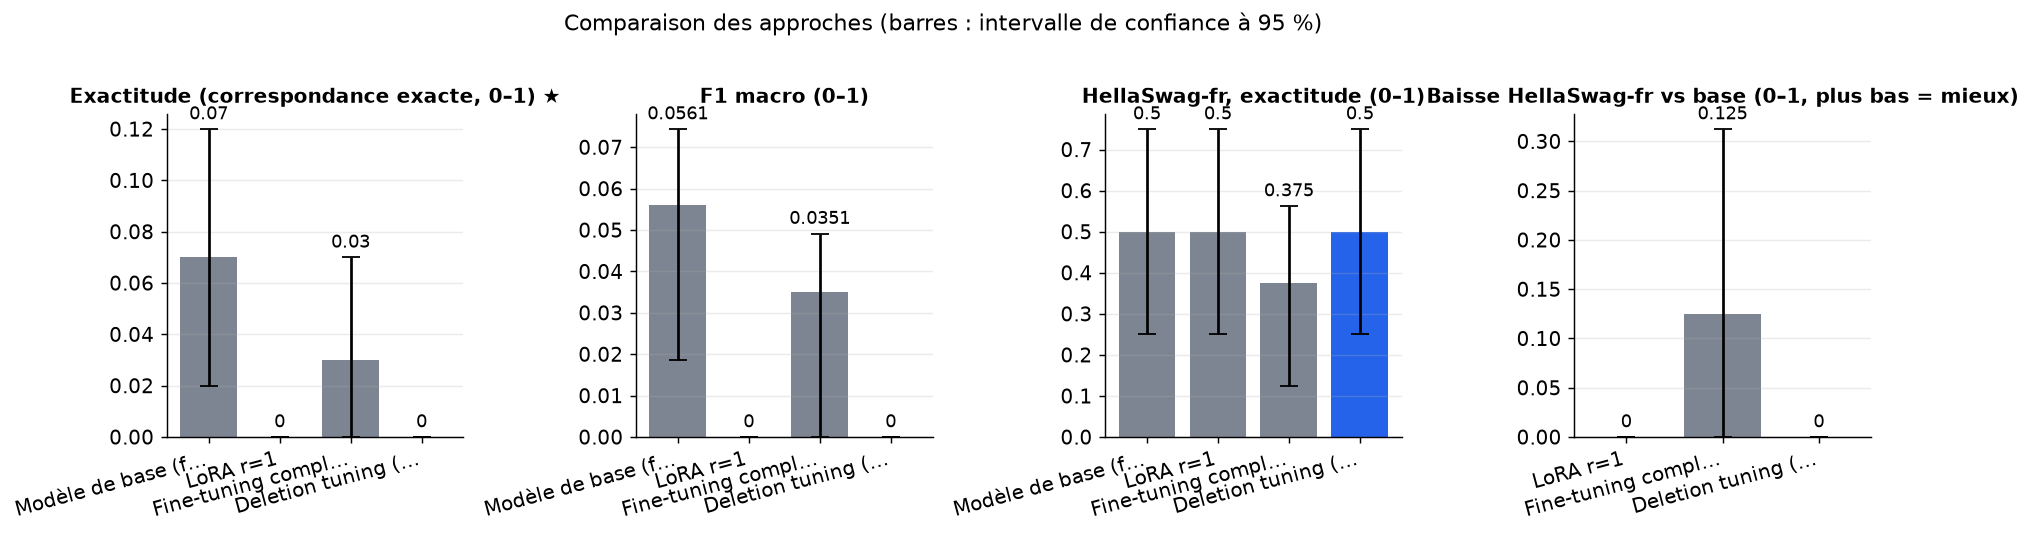

*Figure — Une barre par approche et par métrique, avec l'intervalle de confiance à 95 % ; exactitude et F1 : plus haut = mieux ; baisse HellaSwag : plus bas = moins d'oubli.*

In [34]:
METRIC_LABELS = {"exact_match_accuracy": "Exactitude (correspondance exacte, 0–1)",
                 "macro_f1": "F1 macro (0–1)",
                 "hellaswag_fr_accuracy": "HellaSwag-fr, exactitude (0–1)",
                 "hellaswag_fr_accuracy_drop": "Baisse HellaSwag-fr vs base (0–1, plus bas = mieux)",
                 "adapter_size_mb": "Taille de l'adaptateur (Mo)",
                 "trainable_parameters": "Paramètres entraînés"}
approaches, INVALID_RATES = [], {}
run_note = (f"Exécution : {RUN_INFO['attention']}, {RUN_INFO['calcul']}, {RUN_INFO['matériel']}, "
            f"transformers {RUN_INFO['transformers']}, micro-lots de {MICRO_BATCH_SIZE}.")
for name, role in ARM_ROLES.items():
    metrics, ci, invalid = ARM_METRICS[name]
    INVALID_RATES[name] = invalid
    status = "exploitable" if ADAPTED[name] else f"non exploitable ({ADAPTATION.loc[name, 'motif']})"
    flat = degenerate_keys(ci)
    flat_note = f" IC dégénérés (largeur nulle, sans valeur de mesure) : {', '.join(flat)}." if flat else ""
    if flat:
        print(f"Attention : « {name} » a des intervalles de largeur nulle : {', '.join(flat)}")
    approaches.append({"name": name, "role": role, "metrics": metrics, "ci95": ci,
                       "latency_ms": latency_summary(ARM_OUTPUTS[name]["latencies_ms"][:n_evaluated]),
                       "notes": f"{ARM_OUTPUTS[name]['notes']} Sorties hors liste : {invalid:.1%}. "
                                f"Contrôle d'adaptation : {status}.{flat_note} {run_note}"})

results = save_results({"primary_metric": "exact_match_accuracy", "direction": "max", "metric_labels": METRIC_LABELS,
                        "dataset": {"name": DATA_NAME, "config": DATA_CONFIG, "split": "test",
                                    "n_examples": int(n_evaluated)},
                        "approaches": approaches})
display(results_table(results))
plot_comparison(results, metrics=["exact_match_accuracy", "macro_f1", "hellaswag_fr_accuracy",
                                  "hellaswag_fr_accuracy_drop"],
                caption="Une barre par approche et par métrique, avec l'intervalle de confiance à 95 % ; "
                        "exactitude et F1 : plus haut = mieux ; baisse HellaSwag : plus bas = moins d'oubli.")

### Verdict sur l'hypothèse

L'hypothèse a deux volets, tous deux testés par **bootstrap apparié** sur les mêmes exemples :
1. exactitude du masque ≥ 95 % de celle du FFT, c'est-à-dire $\text{acc}_{\text{masque}} - 0{,}95\,\text{acc}_{\text{FFT}} > 0$ ;
2. baisse HellaSwag du masque inférieure d'au moins 1 point à celle de LoRA, c'est-à-dire $\text{acc}^{\text{HS}}_{\text{masque}} - \text{acc}^{\text{HS}}_{\text{LoRA}} - 0{,}01 > 0$.

Garde commune : un volet est **non concluant, l'adaptation n'a pas eu lieu** dès qu'un de ses bras n'est pas exploitable. C'est le cas du FFT et du masque pour le volet 1, de LoRA et du masque pour le volet 2. Sinon, le volet est **atteint** si tout l'intervalle est au-dessus de 0, **non atteint** s'il est tout entier en dessous, et **non tranché** s'il contient 0. Un intervalle de largeur nulle est déclaré **dégénéré**, donc non concluant.

In [35]:
def correct_vector(name: str) -> np.ndarray:
    """Réussite exemple par exemple (1/0) d'un bras sur le jeu évalué commun."""
    return (np.array(ARM_OUTPUTS[name]["predictions"][:n_evaluated], dtype=object) == gold).astype(float)


def decide(low: float, high: float) -> str:
    """Verdict à partir de l'intervalle de la marge : dégénéré, atteint, non atteint ou non tranché."""
    if high - low <= 1e-12:
        return "non concluant : IC dégénéré (largeur nulle)"
    if low > 0:
        return "atteint"
    if high < 0:
        return "non atteint"
    return "non tranché : l'intervalle contient le seuil"


def verdict_row(criterion: str, arms: tuple[str, str], first, second, margin) -> dict:
    """Ligne de verdict : non concluant si un bras n'est pas exploitable, sinon décision sur l'IC apparié."""
    issues = [f"{arm} : {ADAPTATION.loc[arm, 'motif']}" for arm in arms if not ADAPTED[arm]]
    if issues:
        return {"critère": criterion, "marge": None, "IC 95 %": None,
                "verdict": "non concluant : l'adaptation n'a pas eu lieu (" + " | ".join(issues) + ")"}
    value, low, high = bootstrap_ci(first, second, margin)
    return {"critère": criterion, "marge": round(value, 3), "IC 95 %": f"[{low:+.3f}, {high:+.3f}]",
            "verdict": decide(low, high)}


verdicts = [verdict_row("exactitude masque ≥ 95 % du FFT", (FFT_ARM, MASK_ARM), correct_vector(FFT_ARM),
                        correct_vector(MASK_ARM), lambda f, m: float(np.mean(m) - 0.95 * np.mean(f)))]
mask_control, lora_control = ARM_OUTPUTS[MASK_ARM]["control_correct"], ARM_OUTPUTS[LORA_ARM]["control_correct"]
if mask_control is None or lora_control is None:
    verdicts.append({"critère": "oubli masque < oubli LoRA − 1 pt", "marge": None, "IC 95 %": None,
                     "verdict": "sans objet : pas de jeu de contrôle d'oubli"})
else:
    verdicts.append(verdict_row("oubli masque < oubli LoRA − 1 pt", (LORA_ARM, MASK_ARM), lora_control,
                                mask_control, lambda l, m: float(np.mean(m) - np.mean(l) - 0.01)))
display(pd.DataFrame(verdicts))

,critère,marge,IC 95 %,verdict
0,exactitude masque ≥ 95 % du FFT,None,None,non concluant : l'adaptation n'a pas eu lieu (...
1,oubli masque < oubli LoRA − 1 pt,None,None,non concluant : l'adaptation n'a pas eu lieu (...


## 6. Analyse des résultats

### Exactitude selon la longueur du texte

Une demande courte contient peu d'indices, une longue peut en mêler plusieurs. On découpe le jeu évalué en trois tiers de longueur (en tokens) et on compare l'exactitude des quatre bras dans chaque tiers. Si l'écart entre le masque et le FFT se concentre dans un tiers, on sait où chercher.

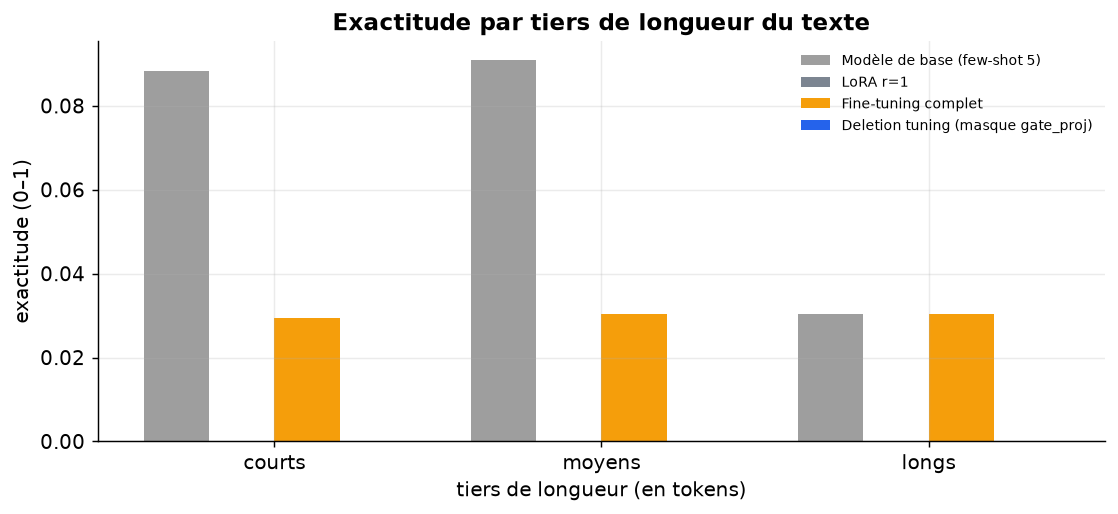

*Figure — Exactitude de chaque approche sur les textes courts, moyens et longs (tiers du jeu évalué) ; des barres proches indiquent un écart indépendant de la longueur.*

,Modèle de base (few-shot 5),LoRA r=1,Fine-tuning complet,Deletion tuning (masque gate_proj)
length_group,,,,
courts,0.088,0.0,0.029,0.0
moyens,0.091,0.0,0.030,0.0
longs,0.030,0.0,0.030,0.0


In [36]:
ARM_COLORS = {BASE_ARM: "#9e9e9e", LORA_ARM: COLORS["reference"], FFT_ARM: COLORS["accent"], MASK_ARM: COLORS["new"]}
evaluated = test.iloc[:n_evaluated].copy()
token_lengths = evaluated["text"].map(lambda t: len(tokens(t)))
evaluated["length_group"] = pd.qcut(token_lengths.rank(method="first"), 3, labels=["courts", "moyens", "longs"])
for name in ARM_ROLES:
    evaluated[name] = correct_vector(name).astype(bool)
by_length = evaluated.groupby("length_group", observed=True)[list(ARM_ROLES)].mean()

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.2
for offset, name in enumerate(ARM_ROLES):
    ax.bar(np.arange(len(by_length)) + (offset - 1.5) * width, by_length[name].to_numpy(), width,
           label=name, color=ARM_COLORS[name])
ax.set_xticks(np.arange(len(by_length)), [str(g) for g in by_length.index])
ax.set(title="Exactitude par tiers de longueur du texte", xlabel="tiers de longueur (en tokens)",
       ylabel="exactitude (0–1)")
ax.legend(fontsize=8)
save_figure(fig, "accuracy_by_length", "Exactitude de chaque approche sur les textes courts, moyens et longs "
            "(tiers du jeu évalué) ; des barres proches indiquent un écart indépendant de la longueur.")
display(by_length.round(3))

### Où le masque gagne et perd par rapport au FFT

Pour chaque classe, on trace la différence d'exactitude entre le masque et le FFT, triée. En vert, le masque fait mieux ; en rouge, il fait moins bien. Avec peu d'exemples par classe, surtout à l'échelle réduite, chaque barre est bruitée : on regarde la forme générale, pas une classe isolée. Si l'un des deux bras n'est pas exploitable, la figure ne décrit que du bruit. En phase `private`, les noms de classes ne sont pas affichés.

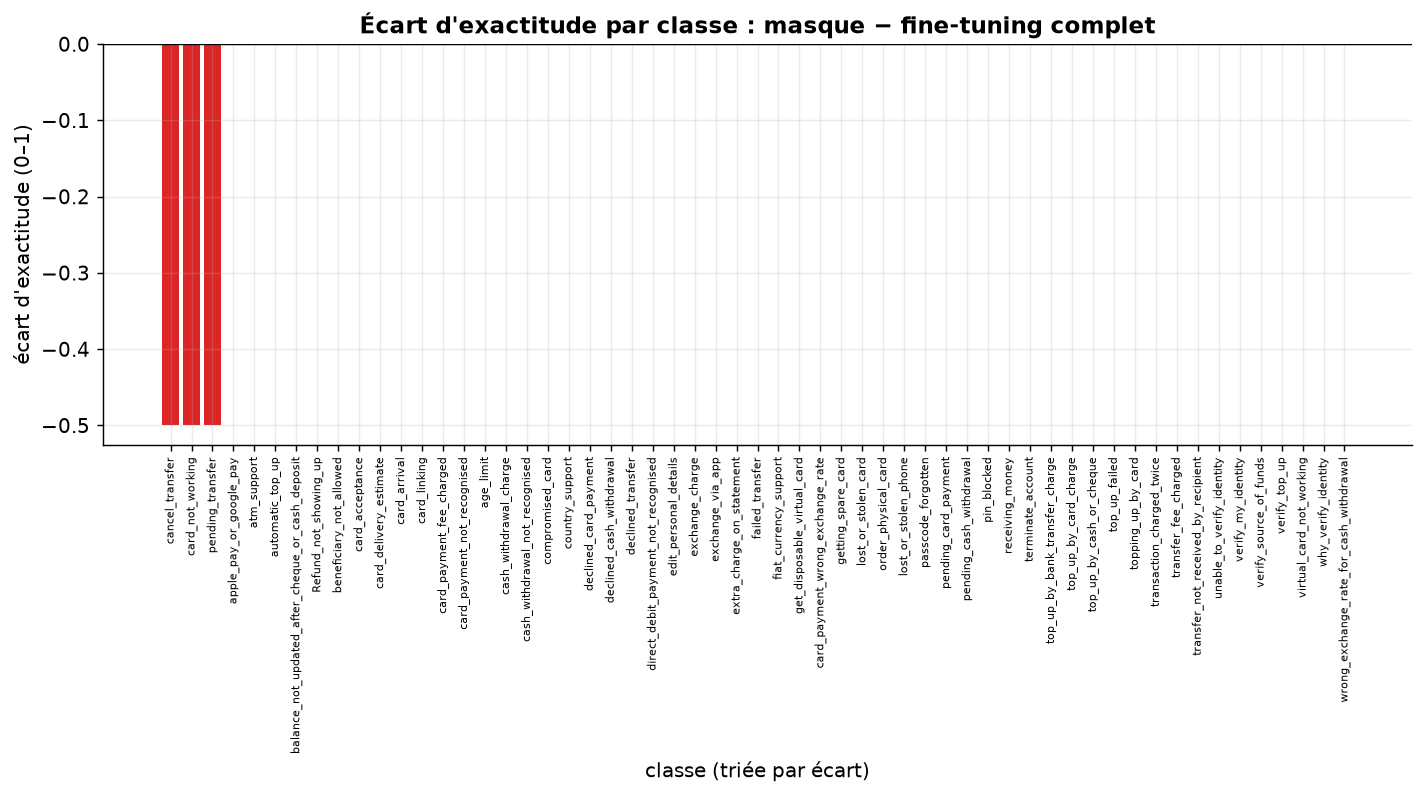

*Figure — Pour chaque classe, exactitude du masque moins celle du fine-tuning complet ; vert : le masque fait mieux, rouge : moins bien. Peu d'exemples par classe : lire la tendance.*

Classes où le masque fait mieux : 0 | moins bien : 3 | à égalité : 54
Masque ou FFT non exploitable : cette figure ne permet aucune conclusion.


In [37]:
per_class = evaluated.groupby("label")[[MASK_ARM, FFT_ARM, LORA_ARM]].mean()
per_class["gap"] = per_class[MASK_ARM] - per_class[FFT_ARM]
per_class = per_class.sort_values("gap")

fig, ax = plt.subplots(figsize=(13, 4))
bar_colors = [COLORS["bad"] if gap < 0 else COLORS["good"] for gap in per_class["gap"]]
ax.bar(np.arange(len(per_class)), per_class["gap"].to_numpy(), color=bar_colors)
if PHASE == "public":
    ax.set_xticks(np.arange(len(per_class)), list(per_class.index), rotation=90, fontsize=6)
else:
    ax.set_xticks([])
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Écart d'exactitude par classe : masque − fine-tuning complet", xlabel="classe (triée par écart)",
       ylabel="écart d'exactitude (0–1)")
save_figure(fig, "per_class_gap", "Pour chaque classe, exactitude du masque moins celle du fine-tuning complet ; "
            "vert : le masque fait mieux, rouge : moins bien. Peu d'exemples par classe : lire la tendance.")
print(f"Classes où le masque fait mieux : {(per_class['gap'] > 0).sum()} | moins bien : {(per_class['gap'] < 0).sum()} "
      f"| à égalité : {(per_class['gap'] == 0).sum()}")
if not (ADAPTED[MASK_ARM] and ADAPTED[FFT_ARM]):
    print("Masque ou FFT non exploitable : cette figure ne permet aucune conclusion.")

### Dynamique d'entraînement et forme du masque

- **À gauche** : la perte SFT par pas des trois bras entraînés, qui voient exactement les mêmes lots. Une perte qui stagne signale un bras sous-entraîné. C'est la première explication à chercher quand un bras est jugé non exploitable.
- **À droite** : la part des poids de `gate_proj` supprimés dans chaque couche, à l'initialisation Wanda puis après entraînement. Elle montre si l'apprentissage concentre les suppressions dans certaines couches. Deux courbes superposées signifient que le masque n'a presque pas bougé.

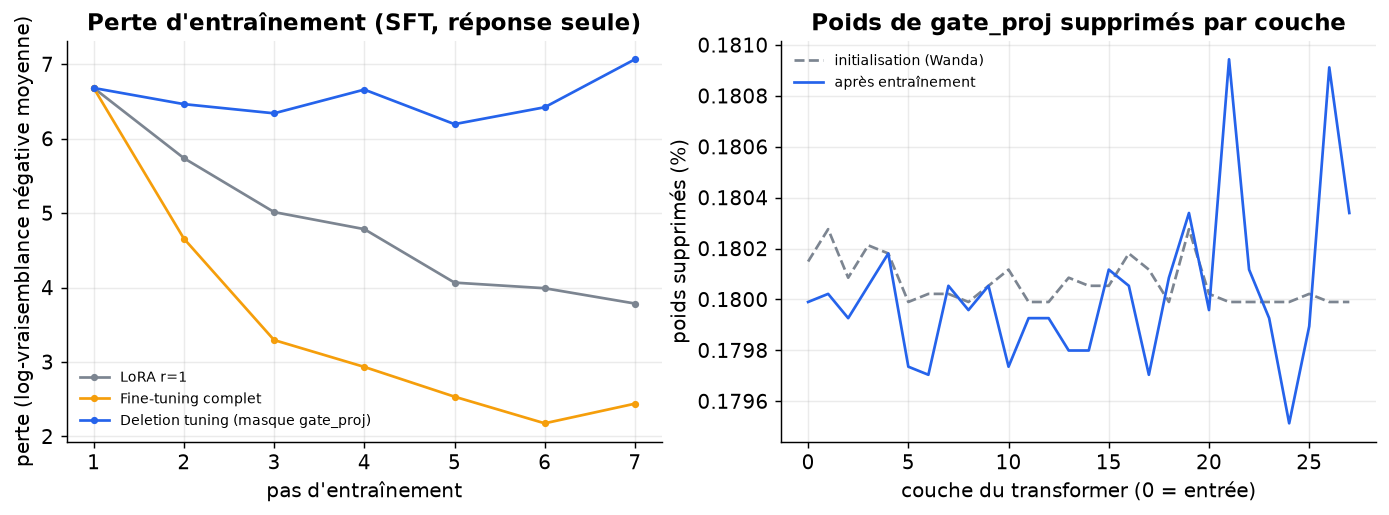

*Figure — À gauche, la perte par pas des trois approches entraînées ; à droite, la part de poids supprimés par couche par le masque, avant (pointillés) et après entraînement.*

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in (LORA_ARM, FFT_ARM, MASK_ARM):
    history = ARM_OUTPUTS[name]["history"]
    axes[0].plot(history["step"], history["loss"], marker="o", markersize=3, label=name, color=ARM_COLORS[name])
axes[0].set(title="Perte d'entraînement (SFT, réponse seule)", xlabel="pas d'entraînement",
            ylabel="perte (log-vraisemblance négative moyenne)")
axes[0].legend(fontsize=8)
layer_index = np.arange(len(MASK_STATS["per_layer_deleted"]))
axes[1].plot(layer_index, 100 * np.array(MASK_STATS["per_layer_initial"]), "--", label="initialisation (Wanda)",
             color=COLORS["reference"])
axes[1].plot(layer_index, 100 * np.array(MASK_STATS["per_layer_deleted"]), label="après entraînement",
             color=COLORS["new"])
axes[1].set(title="Poids de gate_proj supprimés par couche", xlabel="couche du transformer (0 = entrée)",
            ylabel="poids supprimés (%)")
axes[1].legend(fontsize=8)
save_figure(fig, "training_and_mask", "À gauche, la perte par pas des trois approches entraînées ; à droite, "
            "la part de poids supprimés par couche par le masque, avant (pointillés) et après entraînement.")

### Sorties hors liste et exemples d'erreurs

Une sortie hors de la liste des classes (nom inventé, faute de frappe, texte libre) compte comme une erreur. Son taux dit si le modèle a appris le **vocabulaire** des classes, et pas seulement leur sens. On le remet à côté du contrôle d'adaptation. On affiche ensuite quelques erreurs du masque à côté de la réponse du FFT, en phase publique uniquement : aucun texte interne n'est jamais affiché.

In [39]:
summary = pd.DataFrame({"exactitude": {name: float(evaluated[name].mean()) for name in ARM_ROLES},
                        "sorties hors liste": INVALID_RATES,
                        "exploitable": ADAPTED})
display(summary.round(3))

if PHASE == "public":
    mask_wrong = ~evaluated[MASK_ARM].to_numpy()
    errors = evaluated.loc[mask_wrong, ["text", "label"]].copy()
    errors["masque"] = np.array(ARM_OUTPUTS[MASK_ARM]["predictions"][:n_evaluated], dtype=object)[mask_wrong]
    errors["FFT"] = np.array(ARM_OUTPUTS[FFT_ARM]["predictions"][:n_evaluated], dtype=object)[mask_wrong]
    print(f"Erreurs du masque : {mask_wrong.sum()} sur {n_evaluated} ; exemples :")
    display(errors.head(8))

,exactitude,sorties hors liste,exploitable
Modèle de base (few-shot 5),0.07,0.87,True
LoRA r=1,0.00,1.00,False
Fine-tuning complet,0.03,0.96,False
Deletion tuning (masque gate_proj),0.00,1.00,False


Erreurs du masque : 100 sur 100 ; exemples :


,text,label,masque,FFT
0,"Je souhaite un compte pour mes enfants, commen...",age_limit,aider les parents à comprendre comment créer u...,create_account
1,Combien de temps faut-il pour que le transfert...,pending_transfer,Étudier la durée de l'effet du,transfer
2,Que dois-je faire pour transférer mon salaire ...,receiving_money,To tell someone how to transfer money from one...,transfer_to_account
3,J'ai accidentellement effectué une transaction...,cancel_transfer,Je voudrais me faire aider à la vie.,invalid_card_payment
4,"Comment geler ma carte bancaire, suite à un re...",cash_withdrawal_not_recognised,Motiver les enfants à se préparer à la vie en,card_removal
5,La carte que j'ai ne fonctionne pas.,card_not_working,To tell someone that the map is not working.,card_not_working
6,Je pensais que les transferts étaient gratuits...,transfer_fee_charged,"To express that the transfer was free, but the...",charge_of_transfer
7,Le transfert que je viens d'effectuer doit êtr...,cancel_transfer,"To express that the transfer has been made, bu...",cancel_transfer


### À retenir

- **Garde-fou d'abord** : si un bras n'est pas exploitable (exactitude pas au-dessus du trivial, ou sorties identiques au modèle de base), chaque volet qui l'utilise s'affiche **non concluant : l'adaptation n'a pas eu lieu**. C'est attendu à l'échelle réduite, avec ses quelques pas d'entraînement. Aucune marge ni aucun intervalle de largeur nulle ne doit alors être lu comme un résultat.
- **Qualité** : si le masque et le FFT sont exploitables, on compare l'exactitude du masque à 95 % de celle du FFT, avec le verdict apparié de la section 6. À 0,6 B paramètres, un écart en faveur du FFT reste cohérent avec l'article, qui ne revendique l'égalité qu'à plus grande échelle.
- **Oubli** : si le masque et LoRA sont exploitables et que la baisse HellaSwag du masque est nettement plus faible, la promesse « adapter sans oublier » tient en français. Si les intervalles se recouvrent, l'expérience ne permet pas de trancher, ce qui est fréquent avec quelques centaines d'exemples de contrôle.
- **Coût** : le masque compressé fait quelques Mo, comme l'adaptateur LoRA. Le FFT demande, lui, de stocker des centaines de Mo par tâche. L'entraînement du masque garde en revanche un logit par poids de `gate_proj`, donc plus de mémoire que LoRA, mais bien moins que le FFT.
- **Portée** : un seul passage par bras, sur une tâche traduite automatiquement. Une décision dans l'environnement cible demande de répéter l'expérience sur plusieurs tirages et sur un jeu de contrôle interne.

## 7. Bilan

> **Verdict** (confiance faible). À l'échelle réduite (100 exemples d'entraînement, 7 pas, 100 de test, 16 de contrôle d'oubli), aucun bras entraîné n'a appris la tâche. L'exactitude est de 0 % pour le masque et LoRA r=1 et de 3 % pour le fine-tuning complet, contre 7 % pour le modèle de base, avec 96 à 100 % de sorties hors liste. Le masque pèse 0,13 Mo (contre 0,69 Mo pour LoRA) pour 88 M de paramètres entraînés, mais seuls 1 223 poids ont basculé depuis l'initialisation Wanda. Les deux volets de l'hypothèse (95 % du fine-tuning complet, moins d'oubli que LoRA) sont donc non concluants. Ces chiffres ne permettent pas de trancher et ne sont pas comparables à ceux de l'article (autre tâche, autre taille, SFT). Les points ouverts avant toute décision sont la capacité d'apprentissage du masque avec ces réglages, le contrôle d'oubli sur trop peu d'exemples et l'absence de répétition.

*Échelle réduite seulement (100 exemples, CPU) : exception (cellule 45, section reference). Ces chiffres valident la mécanique ; ils sont indicatifs et à confirmer avec `SCALE = "full"`.*

| Approche | Exactitude (correspondance exacte) ★ ↑ | F1 macro ↑ | HellaSwag-fr, exactitude ↑ | Baisse HellaSwag-fr ↓ | Taille de l'adaptateur (Mo) ↓ | Paramètres entraînés | Latence médiane (ms) ↓ |
|---|---|---|---|---|---|---|---|
| Modèle de base (few-shot 5) (référence) | **0,07 [0,02 ; 0,12]** | **0,0561 [0,0187 ; 0,0744]** | **0,5 [0,25 ; 0,75]** | — | — | — | 1,11e+03 |
| LoRA r=1 (référence) | 0 [0 ; 0] | 0 [0 ; 0] | **0,5 [0,25 ; 0,75]** | 0 [0 ; 0] | 0,688 | 3,44e+05 | 310 |
| Fine-tuning complet (référence) | 0,03 [0 ; 0,07] | 0,0351 [0 ; 0,0491] | 0,375 [0,125 ; 0,562] | 0,125 [0 ; 0,312] | 881 | 4,4e+08 | 308 |
| Deletion tuning (masque gate_proj) (nouvelle approche) | 0 [0 ; 0] | 0 [0 ; 0] | **0,5 [0,25 ; 0,75]** | 0 [0 ; 0] | 0,129 | 8,81e+07 | 410 |

★ métrique principale · ↑ plus haut = meilleur · ↓ plus bas = meilleur · entre crochets : intervalle de confiance à 95 % (bootstrap) · en gras : la meilleure valeur.

**Réserves**

- Si le masque ne réussit pas à apprendre, il se comporte comme un simple élagage Wanda. Un mauvais score serait alors dû aux réglages de cette réimplémentation, pas à la méthode des auteurs.
- Le volet « moins d'oubli » n'est pas mesurable avec 16 exemples : le moindre écart observé est du bruit.

**Limites**

- Une seule exécution par bras : la variance due à la graine et à l'échantillon d'entraînement n'est pas mesurée.
- Jeu traduit automatiquement et textes courts : la difficulté diffère sans doute de celle de demandes réelles.
- Modèle de 0,6 B paramètres, taille où les auteurs eux-mêmes n'observent pas l'égalité avec le fine-tuning complet. Il y a aussi un écart avec la source : SFT au lieu de GRPO, calendrier de température choisi par nous.
- Le contrôle d'oubli porte sur 500 exemples HellaSwag : un écart de 1 point reste proche de la résolution du test.
- À l'échelle réduite, trop peu de pas pour adapter les modèles : aucune conclusion n'en est tirée, seulement la validation du code.

**Échelle réduite : ce qui diffère de l'échelle complète**

- À l'échelle réduite, sur CPU : 100 exemples d'entraînement (7 pas), 100 de test et 16 de contrôle HellaSwag. Les textes et les contextes sont plafonnés à 64 tokens, les micro-lots font 4 exemples et la calibration Wanda utilise 16 exemples. Les bras entraînés n'apprennent alors généralement pas la tâche : les verdicts s'affichent « non concluant : l'adaptation n'a pas eu lieu ». C'est le comportement attendu à cette échelle.

**Améliorations possibles**

- Sans répétition ni réglage, les écarts proches de l'intervalle de confiance ne permettent pas de classer les approches.
- L'avantage de taille du masque sur LoRA vient en partie de la compression et d'un masque qui reste proche de l'initialisation, pas seulement de ce qui a été appris.
- Les écarts de latence reflètent surtout la longueur de l'invite et des sorties générées, pas le coût de la méthode.

**Et ensuite ?** Rejouer le même protocole sur vos données : `PHASE = "private"`, `SCALE = "full"`, après avoir préparé le jeu et la configuration décrits dans le README (section « Sur vos données »).